# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

Prof Luis Eduardo Falcón Morales

Actividad de Semana 3

### **Rotación de Personal - IBM**

* **Nombre:** MIGUEL LABRA LORENZANA

* **matrícula:** A01363726

------------

* **LLM utilizado:** Claude (Anthropic), como apoyo para errores conceptuales del codigo, revisar la redacción y contrastar mis interpretaciones.


* #### **En esta actividad puedes apoyarte en uno o varios Modelos de Lenguaje de Gran Tamaño, LLM por sus siglas en inglés (Large Language Model). Indica claramente cuál o cuáles utilizaste.**

* #### **La siguiente actividad se basa en los datos del archivo "WA_Fn-UseC_-HR-Employee-Attrition.csv" que se encuentra en la siguiente liga de Kaggle, llamada "IBM HR Analytics Employee Attrition & Performance".**

* #### **Los datos los proporcionó IBM y aunque comentaron que por cuestiones de privacidad los datos son sintéticos, los generaron con base a su experiencia. Estos datos en general son referencia cuando se habla en Estadística o Aprendizaje Automático sobre el tema de rotación de personal.**

**El archivo contiene 1470 registros:**

https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset


# **Ejercicio 1:**

#### **Incluye una breve introducción sobre lo que se entiende por el problema de rotación de personal en las organizaciones (employee attrition problem).**

El problema de rotación de personal en las organizaciones se trata de cuando un empleado renuncia, esto implica que la organización debe invertir en tiempo y dinero en buscar cubrir el puesto. De igual forma esta deserción del empleado provocará que las actividades que solía hacer se asignen a otro colaborador o incluso se dejen de hacer. El reto para la organización es anticipar estas salidas y tratar de retener al empleado.

Dicho de otra forma, el problema no es solo que alguien se vaya, sino lo que cuesta cada salida: reclutar, capacitar a la persona que llega y esperar a que sea tan productiva como la anterior, además de perder el conocimiento y las relaciones que se llevó el colaborador. Por eso, en lugar de reaccionar cuando la renuncia ya ocurrió, conviene usar datos históricos (edad, puesto, sueldo, horas extra, satisfacción, antigüedad, etc.) de empleados que se fueron y de los que se quedaron para identificar patrones y estimar qué perfiles tienen mayor riesgo de salida. Con eso Recursos Humanos puede priorizar acciones de retención. Desde el punto de vista de aprendizaje automático, esto se plantea como un problema de **clasificación binaria** (Attrition = Yes/No) sobre un conjunto de datos con clases desbalanceadas.

In [27]:
# Agrega aquí todas las librerías adicionales o paquetes que consideres necesarias:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier


from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import cross_validate

from sklearn.preprocessing import OrdinalEncoder

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

import warnings
warnings.filterwarnings('ignore')   # evita avisos de deprecación de sklearn en la salida


* #### **Descarga el archivo de datos de la página de Kaggle.**

* #### **Cargamos el archivo como un DataFrame de Pandas y hacemos uso del método “describe” con el argumento include= “all” para desplegar información de todas las variables, numéricas y categóricas.**

In [28]:
path = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
data = pd.read_csv(path)

print("Tamaño del DataFrame:", data.shape)
data.describe(include = 'all').T

Tamaño del DataFrame: (1470, 35)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


# **Ejercicio 2:**

**a) Realiza los análisis descriptivos y/o gráficos que creas adecuados para identificar 4 factores que se deben eliminar desde un inicio.**

**Al nuevo DataFrame sin las variables indicadas, llamarlo df.**

In [29]:
data.isna().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [30]:
data.nunique()

Age                           43
Attrition                      2
BusinessTravel                 3
DailyRate                    886
Department                     3
DistanceFromHome              29
Education                      5
EducationField                 6
EmployeeCount                  1
EmployeeNumber              1470
EnvironmentSatisfaction        4
Gender                         2
HourlyRate                    71
JobInvolvement                 4
JobLevel                       5
JobRole                        9
JobSatisfaction                4
MaritalStatus                  3
MonthlyIncome               1349
MonthlyRate                 1427
NumCompaniesWorked            10
Over18                         1
OverTime                       2
PercentSalaryHike             15
PerformanceRating              2
RelationshipSatisfaction       4
StandardHours                  1
StockOptionLevel               4
TotalWorkingYears             40
TrainingTimesLastYear          7
WorkLifeBa

In [31]:
list(data['EmployeeNumber'])

[1,
 2,
 4,
 5,
 7,
 8,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 26,
 27,
 28,
 30,
 31,
 32,
 33,
 35,
 36,
 38,
 39,
 40,
 41,
 42,
 45,
 46,
 47,
 49,
 51,
 52,
 53,
 54,
 55,
 56,
 57,
 58,
 60,
 61,
 62,
 63,
 64,
 65,
 68,
 70,
 72,
 73,
 74,
 75,
 76,
 77,
 78,
 79,
 80,
 81,
 83,
 84,
 85,
 86,
 88,
 90,
 91,
 94,
 95,
 96,
 97,
 98,
 100,
 101,
 102,
 103,
 104,
 105,
 106,
 107,
 110,
 112,
 113,
 116,
 117,
 118,
 119,
 120,
 121,
 124,
 125,
 126,
 128,
 129,
 131,
 132,
 133,
 134,
 137,
 138,
 139,
 140,
 141,
 142,
 143,
 144,
 145,
 147,
 148,
 150,
 151,
 152,
 153,
 154,
 155,
 158,
 159,
 160,
 161,
 162,
 163,
 164,
 165,
 167,
 169,
 170,
 171,
 174,
 175,
 176,
 177,
 178,
 179,
 182,
 183,
 184,
 190,
 192,
 193,
 194,
 195,
 197,
 198,
 199,
 200,
 201,
 202,
 204,
 205,
 206,
 207,
 208,
 211,
 214,
 215,
 216,
 217,
 218,
 221,
 223,
 224,
 226,
 227,
 228,
 230,
 231,
 233,
 235,
 238,
 239,
 240,
 241,
 242,
 243,
 244,
 245,
 2

In [32]:
data['EmployeeCount'].value_counts()

EmployeeCount
1    1470
Name: count, dtype: int64

In [33]:
data['StandardHours'].value_counts()

StandardHours
80    1470
Name: count, dtype: int64

In [34]:
data['Over18'].value_counts()

Over18
Y    1470
Name: count, dtype: int64

In [35]:
data.dtypes

Age                          int64
Attrition                   object
BusinessTravel              object
DailyRate                    int64
Department                  object
DistanceFromHome             int64
Education                    int64
EducationField              object
EmployeeCount                int64
EmployeeNumber               int64
EnvironmentSatisfaction      int64
Gender                      object
HourlyRate                   int64
JobInvolvement               int64
JobLevel                     int64
JobRole                     object
JobSatisfaction              int64
MaritalStatus               object
MonthlyIncome                int64
MonthlyRate                  int64
NumCompaniesWorked           int64
Over18                      object
OverTime                    object
PercentSalaryHike            int64
PerformanceRating            int64
RelationshipSatisfaction     int64
StandardHours                int64
StockOptionLevel             int64
TotalWorkingYears   

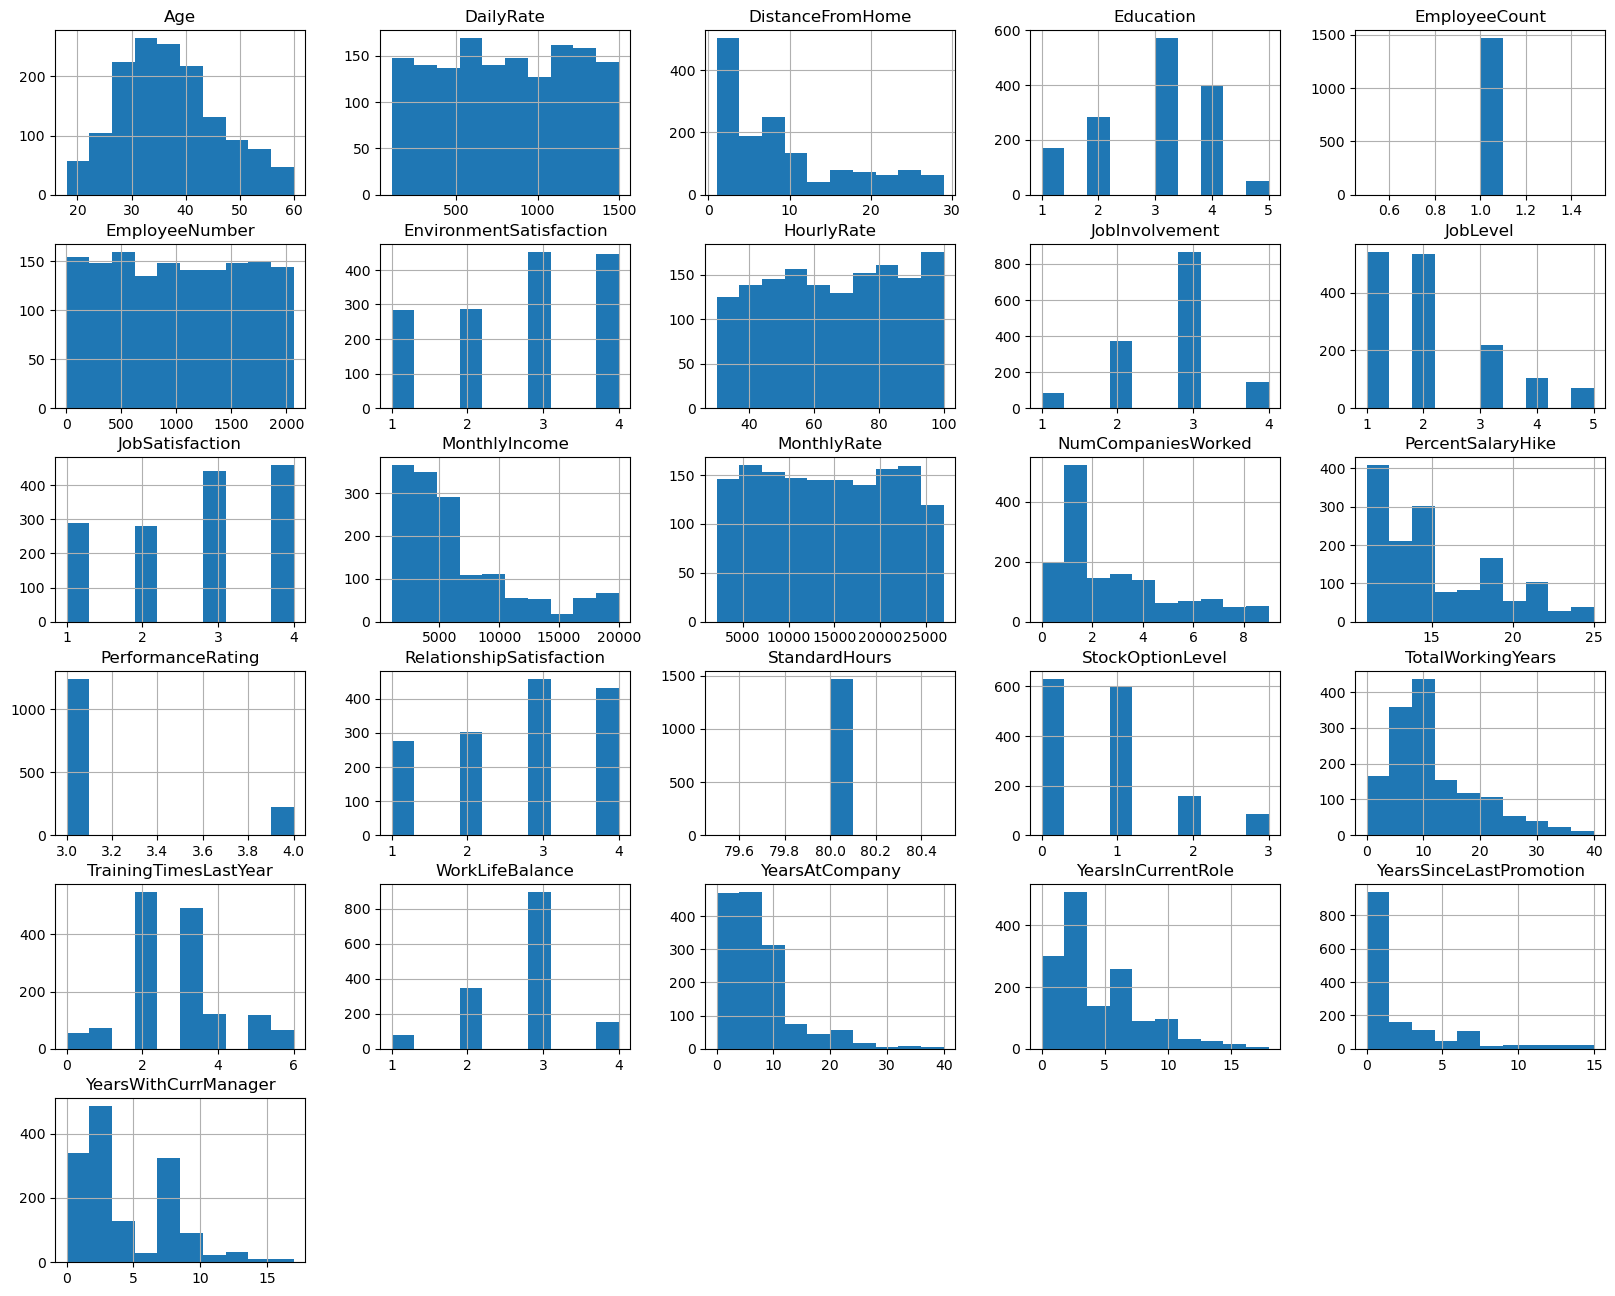

In [36]:
data.hist(figsize=(20,16),legend=False)
plt.show()

In [37]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [38]:
data.shape

(1470, 35)

In [39]:
data_nodup = data.drop_duplicates()
data_nodup.shape

(1470, 35)

In [40]:
columnas = list(data.columns)

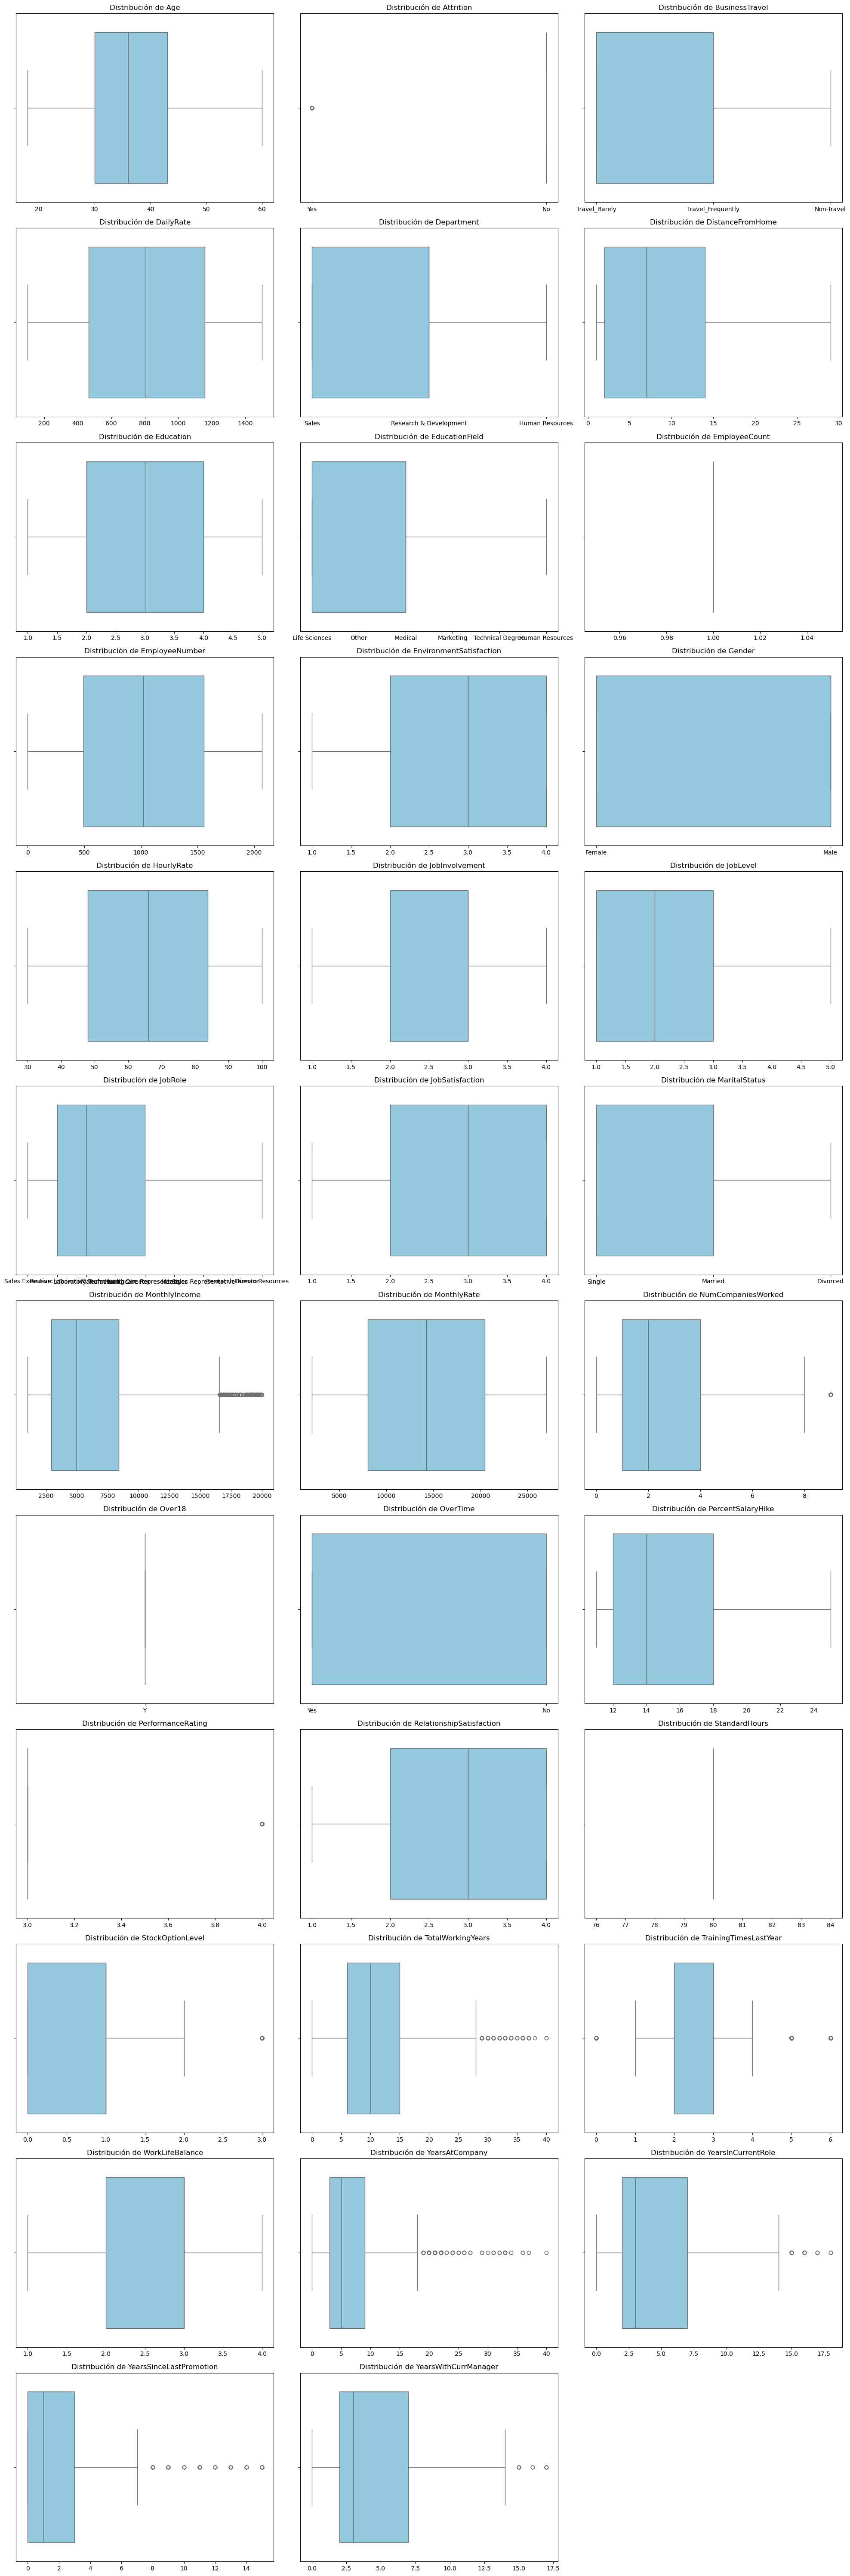

In [41]:
num_cols = 3  # Número de gráficos por fila
num_filas = math.ceil(len(columnas) / num_cols)

fig, axes = plt.subplots(nrows=num_filas, ncols=num_cols, figsize=(20, 5 * num_filas))

axes = axes.flatten()

for i, col in enumerate(columnas):
    sns.boxplot(x=data[col], color='skyblue', ax=axes[i])
    axes[i].set_title(f'Distribución de {col}', fontsize=12)
    axes[i].set_xlabel('') 

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Después de llevar a cabo un breve análisis exploratorio de los datos, notamos que que todos los registros están completos, es decir, no hay valores faltantes. No hay valores duplicados, sí hay outliers pero lo las columnas que generan ruido son aquellas donde los valores son constantes, es decir, que para cada registro se repite el mismo valor. Sumado a eso también la columna de "EmployeeNumber" a pesar de que es la enumeración de cada registro, no aporta nada al desempeño del modelo.

In [42]:
# a) Incluye a continuación el código y celdas que creas adecuados para responder a la pregunta.

# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++


# 1) Variables sin variabilidad: un solo valor en los 1470 registros
constantes = [col for col in data.columns if data[col].nunique() == 1]
print("Variables con un único valor:", constantes)
for col in constantes:
    print(f"  {col}: {data[col].unique().tolist()}")

# 2) Variables identificadoras: un valor distinto por cada registro
print("\n¿EmployeeNumber es único para cada empleado?:", data['EmployeeNumber'].is_unique)
print("Valores distintos / registros:", data['EmployeeNumber'].nunique(), "/", len(data))

# 3) Descartamos otros problemas de calidad que pudieran justificar eliminar algo más
print("\nValores nulos en total:", int(data.isna().sum().sum()))
print("Registros duplicados:", int(data.duplicated().sum()))

# DataFrame sin las 4 variables:
vars_eliminar = constantes + ['EmployeeNumber']
df = data.drop(columns=vars_eliminar)


# ++++++++++ Termina sección para agregar código +++++++++++++++++++++++++++


# Verifiquemos de qué tamaño queda el nuevo DataFrame:
print("Tamaño del nuevo DataFrame:", df.shape)

Variables con un único valor: ['EmployeeCount', 'Over18', 'StandardHours']
  EmployeeCount: [1]
  Over18: ['Y']
  StandardHours: [80]

¿EmployeeNumber es único para cada empleado?: True
Valores distintos / registros: 1470 / 1470

Valores nulos en total: 0
Registros duplicados: 0
Tamaño del nuevo DataFrame: (1470, 31)


**b) Con base a tu análisis anterior, indica cuáles fueron estas 4 variables y la justificación de por qué se pueden eliminar.**

++++++++ Inicia la sección de agregar texto: ++++++++++++

Como se meniono arriba las variables que se eliminan son las variables de valor constante y el número de empleado:

1. **EmployeeCount**: es 1 en los 1470 registros (`value_counts` muestra un único valor). Al no variar, no distingue a quien se va de quien se queda, así que no aporta información al modelo.
2. **StandardHours**: es 80 en todos los registros. Es la misma situación: varianza cero, por lo que no puede explicar la rotación.
3. **Over18**: todos los empleados tienen "Y" (`nunique` = 1). Es una constante categórica y, además, al codificarla solo generaría una columna sin información.
4. **EmployeeNumber**: es un identificador, con 1470 valores distintos para 1470 empleados. No describe una característica del colaborador, sino que solo lo nombra. Esta variable podría generarle ruido al modelo.

Las tres primeras se detectan con `nunique()`, `value_counts()` y con las gráficas, donde se ven como una sola barra o una línea sin dispersión. La cuarta se identifica porque `nunique()` coincide con el número de registros. Ninguna otra variable justifica eliminarse en este punto: no hay valores nulos ni registros duplicados (1470 filas antes y después de `drop_duplicates()`), de modo que el DataFrame `df` queda con 31 columnas (30 de entrada + Attrition).

++++++++ Termina la sección de agregar texto: ++++++++++++

# **Ejercicio 3:**

#### **Una vez eliminadas las variables no deseadas, clasifiquemos las restantes como se indica a continuación y en base a la información dada en la plataforma de Kaggle.**

#### **El número entre corcheas indica el número de variables de dicho tipo y el  número entre paréntesis redondos indica el número de niveles.**

* **Variables numéricas [14]:**

   * NumCompaniesWorked

   * TrainingTimesLastYear

   * Age

   * DailyRate

   * DistanceFromHome

   * HourlyRate

   * MonthlyIncome

   * MonthlyRate

   * PercentSalaryHike

   * TotalWorkingYears

   * YearsAtCompany

   * YearsInCurrentRole

   * YearsSinceLastPromotion

   * YearsWithCurrManager

* **Variables ordinales [9]:**

   * Education (5)

   * EnvironmentSatisfaction (4)

   * JobInvolvement (4)

   * JobLevel (5)

   * JobSatisfaction (4)

   * PerformanceRating (2)

   * RelationshipSatisfaction (4)

   * StockOptionLevel (4)

   * WorkLifeBalance (4)

* **Variables binarias [3]:**

   * Attrition (variable de salida)

   * Gender

   * OverTime

* **Variables nominales [5]:**

   * BusinessTravel (3)

   * Department (3)

   * EducationField (6)

   * JobRole (9)

   * MaritalStatus (3)

**Indpendientemente de los factores que al final el modelo identifique como los factores más importantes a considerar en este problema de rotación de personal ¿qué preocupaciones éticas o legales podrían generarse, si algunos de estos factores más importantes a considerar para tomar decisiones sobre los empleados fueran la edad (Age), el género (Gender) o el estado civil (Marital Status)?**

++++++++ Inicia la sección de agregar texto: ++++++++++++

**Preocupaciones legales.** Edad, género y estado civil son categorías sobre las que existe protección contra la discriminación. En México, el artículo 1.º de la Constitución y el artículo 3.º de la Ley Federal del Trabajo prohíben discriminar por motivos como edad, género o estado civil, y la mayoría de los países cuentan con normas equivalentes. Si el modelo asignara más riesgo (y por lo tanto menos inversión, menos ascensos, menos capacitación o incluso una baja anticipada) a quien tiene cierta edad, es mujer o es soltero(a), la empresa podría estar tomando decisiones laborales discriminatorias aunque el sesgo "venga del algoritmo". 

**Preocupaciones éticas.**

- *Correlación no es causalidad.* Que en los datos haya más renuncias entre los empleados solteros o jóvenes no significa que la edad o el estado civil causen la renuncia. Probablemente reflejan otras circunstancias (puestos iniciales, menores salarios, mayor movilidad laboral). Tomar decisiones sobre la persona por su categoría es tratar a un individuo como un promedio de su grupo.
- *Sesgo histórico.* Si los datos reflejan prácticas pasadas desiguales, el modelo las aprende y las perpetúa. Quitar la columna no basta, porque otras variables (años de experiencia, nivel de puesto, antigüedad) pueden funcionar como sustitutos de la edad.
- *Trato diferente.* Si a quien se marca como "riesgo de salida" se le deja de considerar para proyectos o ascensos, es más probable que termine yéndose, y el modelo parecerá haber acertado.

**Qué haría para mitigarlo:** usar el modelo solo para diseñar acciones de apoyo y retención (no sancionatorias), mantener a una persona que revise cada caso, evaluar el desempeño del modelo por subgrupos, documentar qué variables se usan y por qué, y concentrar las intervenciones en factores que la empresa sí puede modificar.

++++++++ Termina la sección de agregar texto. +++++++++++


In [43]:
# Clasificación de variables del Ejercicio 3 (se usan en los análisis y en el ColumnTransformer)
vars_num = ['NumCompaniesWorked', 'TrainingTimesLastYear', 'Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate',
            'MonthlyIncome', 'MonthlyRate', 'PercentSalaryHike', 'TotalWorkingYears', 'YearsAtCompany',
            'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

vars_ord = ['Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobSatisfaction',
            'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'WorkLifeBalance']

vars_bin = ['Gender', 'OverTime']          # Attrition también es binaria, pero es la variable de salida

vars_nom = ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus']

# Verificación: todas las variables de entrada de df quedan clasificadas, sin repetir ni omitir ninguna
todas = vars_num + vars_ord + vars_bin + vars_nom
print("Numéricas:", len(vars_num), "| Ordinales:", len(vars_ord), "| Binarias (sin Attrition):", len(vars_bin), "| Nominales:", len(vars_nom))
assert len(todas) == len(set(todas))
assert set(todas) == set(df.columns) - {'Attrition'}
print("Todas las variables de entrada quedaron clasificadas:", len(todas))

Numéricas: 14 | Ordinales: 9 | Binarias (sin Attrition): 2 | Nominales: 5
Todas las variables de entrada quedaron clasificadas: 30


# **Ejercicio 4:**

**a) Aunque este problema como está planteado es un problema de clasificación binaria, ¿qué otros enfoques analíticos podrían plantearse y modelarse a partir de este problema? Menciona al menos dos más.**



++++++++ Inicia la sección de agregar texto: ++++++++++++

Además de clasificar si un empleado renunciará o no, el mismo problema se puede abordar desde otros enfoques:

1. **Agrupamiento (clustering).** Con K-Means o clustering jerárquico se pueden segmentar a los empleados en perfiles parecidos (por ejemplo "joven, puesto inicial, con horas extra" frente a "senior, estable, bien pagado") sin usar la etiqueta, y después ver qué tasa de renuncia tiene cada segmento. 
2. **Regresión.** Se pueden hacer predicciones para estimar la antigüedad esperada de un empleado, su nivel de satisfacción o su ingreso mensual, siendo estos como indicadores clave.
3. **Detección de anomalías.** Útil si las renuncias fueran muy poco frecuentes, para identificar perfiles que se salen de lo normal.

++++++++ Termina la sección de agregar texto: ++++++++++++

### **Para esta actividad usaremos una partición en Train, Val y Test, con los porcentajes que se indican a continuación.**

In [44]:
print("Dimensiones y Porcentajes de la partición Train+Validation+Test generada:")
print("-"*75)

X = df.drop(columns='Attrition')
y = df[['Attrition']]

Xtrain, Xtv, ytrain, ytv = train_test_split(X, y, train_size=0.70, stratify=y, random_state=17)
Xval, Xtest, yval, ytest = train_test_split(Xtv, ytv, test_size=0.5, stratify=ytv, random_state=17)

print("Variables de entrada Train, Validation, Test:")
print(Xtrain.shape, '%.1f%%' % (100.*Xtrain.shape[0]/X.shape[0]))
print(Xval.shape, '%.1f%%' % (100.*Xval.shape[0]/X.shape[0])),
print(Xtest.shape, '%.1f%%' % (100.*Xtest.shape[0]/X.shape[0]))

print("\nVariables de salida Train, Validation, Test:")
print(ytrain.shape)
print(yval.shape)
print(ytest.shape)

Dimensiones y Porcentajes de la partición Train+Validation+Test generada:
---------------------------------------------------------------------------
Variables de entrada Train, Validation, Test:
(1029, 30) 70.0%
(220, 30) 15.0%
(221, 30) 15.0%

Variables de salida Train, Validation, Test:
(1029, 1)
(220, 1)
(221, 1)


# **Ejercicio 5:**


**a) Aplica la transformación LabelEncoder() de Sklearn a la variable“Attrition”, tomando en cuenta los siguientes puntos:**

* **Las nuevas variables deberán llamarse ahora: ytrainT, yvalT, ytestT.**

* **Al aplicar la transformación LabelEncoder deberás evitar el filtrado de información (data-leakage).**


In [45]:
# a)
# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++


# El LabelEncoder se ajusta (fit) SOLO con Train; Val y Test solo se transforman (transform).
# Así, la información de Val/Test no participa en el ajuste (evitamos data-leakage).
le = LabelEncoder()

ytrainT = pd.DataFrame(le.fit_transform(np.ravel(ytrain)), columns=['Attrition'], index=ytrain.index)
yvalT   = pd.DataFrame(le.transform(np.ravel(yval)),       columns=['Attrition'], index=yval.index)
ytestT  = pd.DataFrame(le.transform(np.ravel(ytest)),      columns=['Attrition'], index=ytest.index)

print("Clases aprendidas por el LabelEncoder (posición = código):", list(le.classes_))


# +++++++++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++


print('Porcentaje de datos en cada clase del conjunto de entrenamiento (Train):\n', ytrainT['Attrition'].value_counts() / ytrainT.shape[0])

Clases aprendidas por el LabelEncoder (posición = código): ['No', 'Yes']
Porcentaje de datos en cada clase del conjunto de entrenamiento (Train):
 Attrition
0    0.838678
1    0.161322
Name: count, dtype: float64


#### Además, responde las siguientes preguntas:

**b) Con base a la documentación actual de Sklearn, ¿a qué tipo de variables se recomienda aplicar la transformación LabelEncoder?**

**c) Con base al contexto del problema, ¿qué significan los valores 0 (NO) y 1 (YES) de la variable de salida Attrition?**

**d) Con base a la información obtenida y considerando la métrica de la exactitud (accuracy) ¿cuál será el valor del umbral del modelo base o ingenuo (baseline, naive) a superar para evitar tener un modelo subentrenado una vez que empecemos a generarlos?**

**e) Indica si el desbalanceo de clases obtenido puede ya considerarse como un problema, y de considerarlo así, qué otra métrica o métricas podrían ser más adecuadas que la exactitud (accuracy).**



++++++++ Inicia la sección de agregar texto: ++++++++++++

b) Según la documentación de Sklearn, `LabelEncoder` debe usarse para codificar **valores objetivo (la variable de salida y)** y no las variables de entrada X. Convierte etiquetas de una sola columna en enteros de 0 a n_clases-1. Para las variables de entrada se recomienda `OrdinalEncoder` (categorías con orden) u `OneHotEncoder` (categorías sin orden), que trabajan sobre varias columnas a la vez y permiten controlar el orden de las categorías. Aquí lo usamos correctamente porque se aplica a `Attrition`, que es la variable de salida.

c) `LabelEncoder` ordena las etiquetas alfabéticamente, por lo que **0 = "No"** (el empleado se queda en la empresa) y **1 = "Yes"** (el empleado renunció). La clase positiva, la que interesa detectar, es decir, la 1.

d) En el conjunto de entrenamiento, la clase 0 (No) representa aproximadamente el **83.9%** de los datos y la clase 1 (Yes) el 16.1%. Un modelo ingenuo que respondiera siempre "No" (la clase mayoritaria) alcanzaría una exactitud de alrededor de **0.839**. Ese es el umbral a superar: por lo tanto, si un modelo obtiene una exactitud menor o igual a 0.839 estaría subentrenado y justo se buscaría superar esa cantidad.

e) Sí, el desbalanceo ya es un problema. Con 84% de una clase, la exactitud resulta engañosa, ya que un modelo puede tener una exactitud alta sin detectar a casi ninguno de los empleados que sí renuncian, que precisamente son los que interesan. Convendría usar métricas centradas en la clase positiva: justamente para datos desbalanceados se sugiere usar el **f1-score** o la **recall (sensibilidad)** de la clase Yes.

++++++++ Termina la sección de agregar texto. +++++++++++

# **Ejercicio 6:**


#### **Incluye a continuación un análisis gáfico y descriptivo que consideres adecuado.**

  * **a) El análisis debe ser suficiente para que te ayude a tomar las decisiones sobre qué transformaciones aplicar a cada variable antes de entrenar los modelos.**

  * **b) Además, para obtener mayor información sobre la relación entre variables, incluye un gráfico de barras de frecuencias ordenadas de mayor a menor, de la variable "Age", únicamente para los casos de empleados que ya no están en la compañía (Attrition=Yes).**

  * **c) Incluye también un gráfico de barras ordenado de la relación entre Education y Attrition=Yes. Muestra además en el gráfico las etiquetas asociadas a Education en lugar de los números, como se indica en la página de Kaggle.**

  * **d) [Opcional] Incluye algún otro gráfico o gráficos que consideres aporta información para el análisis y entendimiento del problema. Si no encuentras algún otro gráfico de interés, deberas indicarlo.**

  * **e) Para la empresa de IBM ¿qué es más costoso? ¿clasificar erróneamente a un empleado que sí renunciará, o por el contrario, generar una falsa alarma?**


Proporción de cada clase en Attrition:
Attrition
No     0.839
Yes    0.161
Name: proportion, dtype: float64

Asimetría de las variables numéricas:
YearsSinceLastPromotion    1.98
YearsAtCompany             1.76
MonthlyIncome              1.37
TotalWorkingYears          1.12
NumCompaniesWorked         1.03
DistanceFromHome           0.96
YearsInCurrentRole         0.92
YearsWithCurrManager       0.83
PercentSalaryHike          0.82
TrainingTimesLastYear      0.55
Age                        0.41
MonthlyRate                0.02
DailyRate                 -0.00
HourlyRate                -0.03
dtype: float64


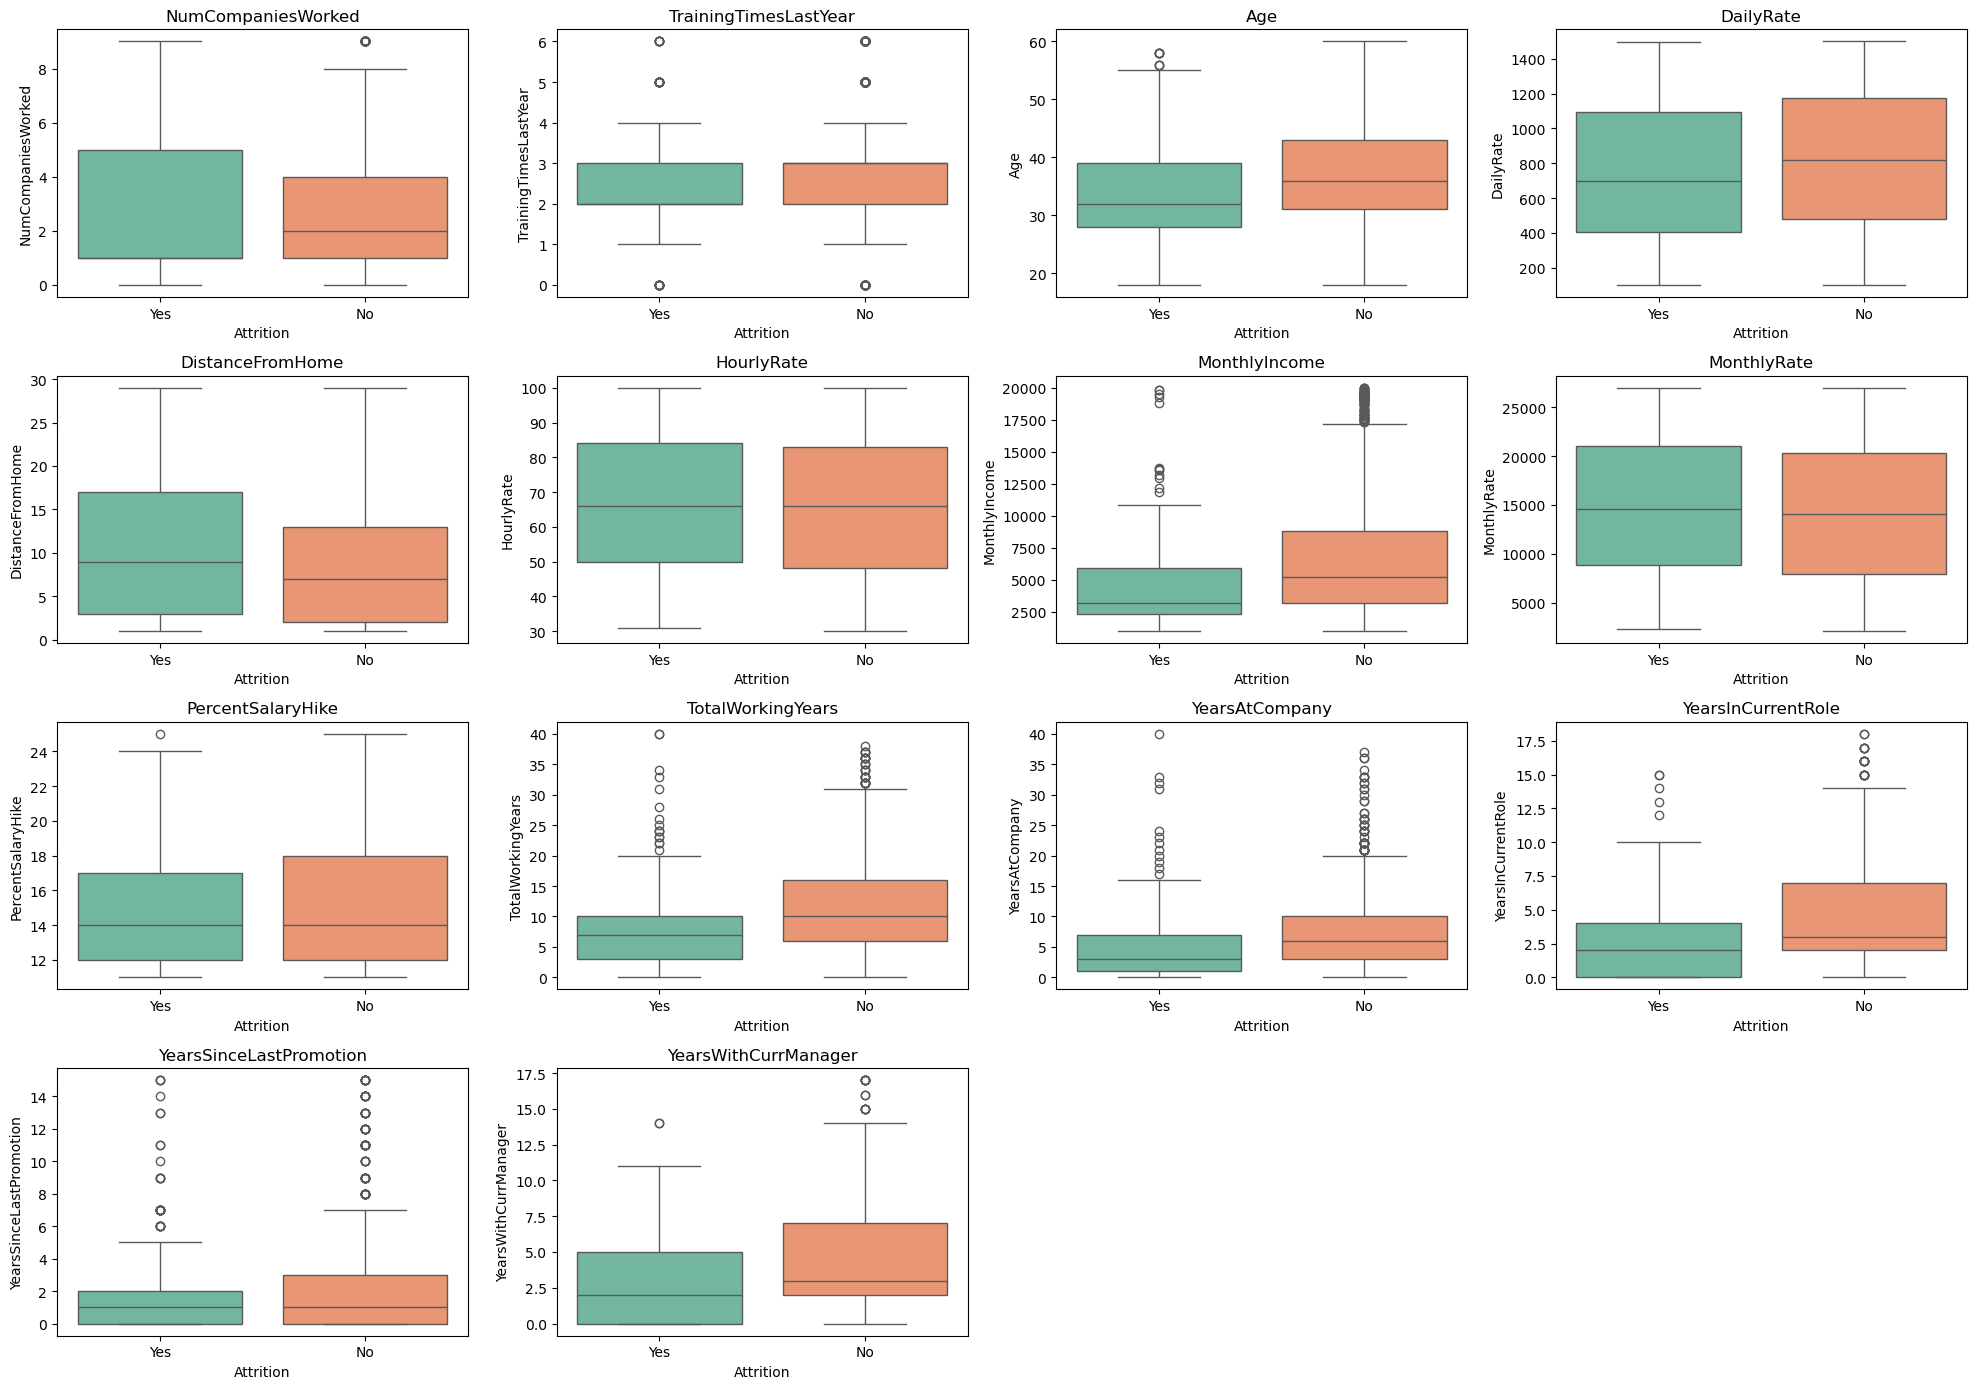

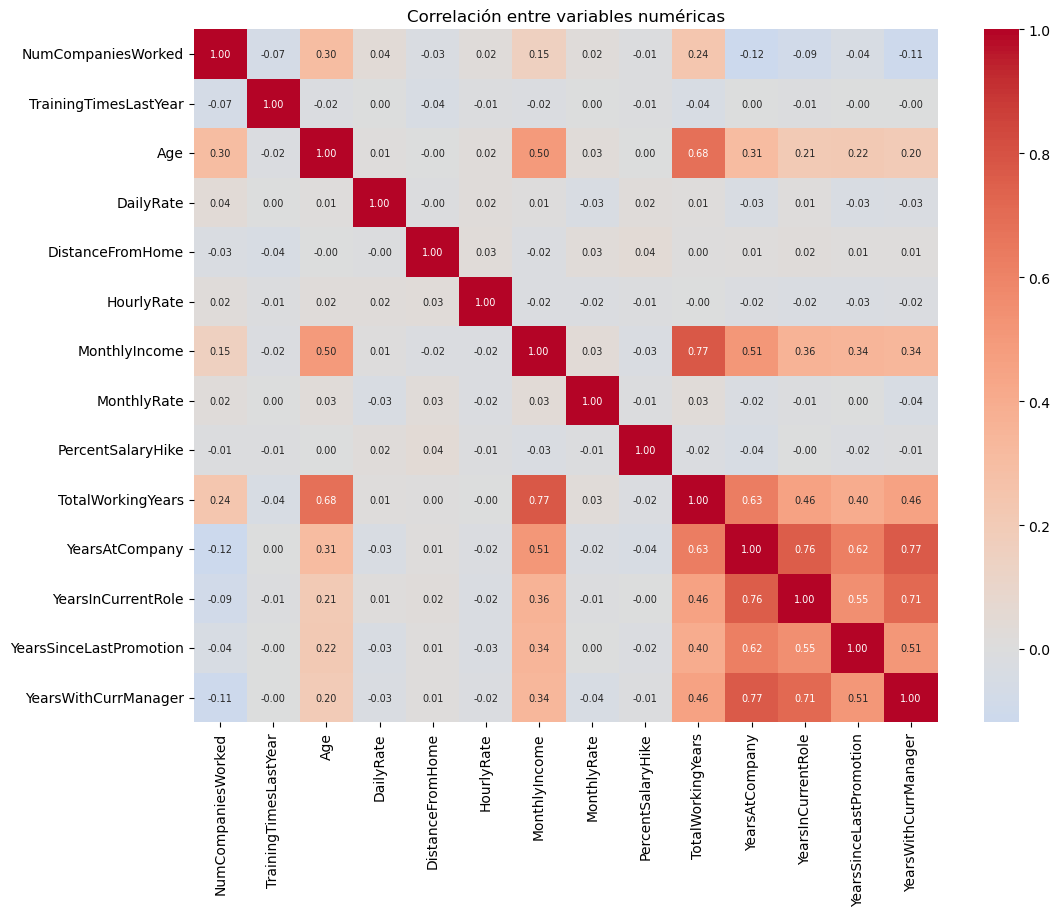

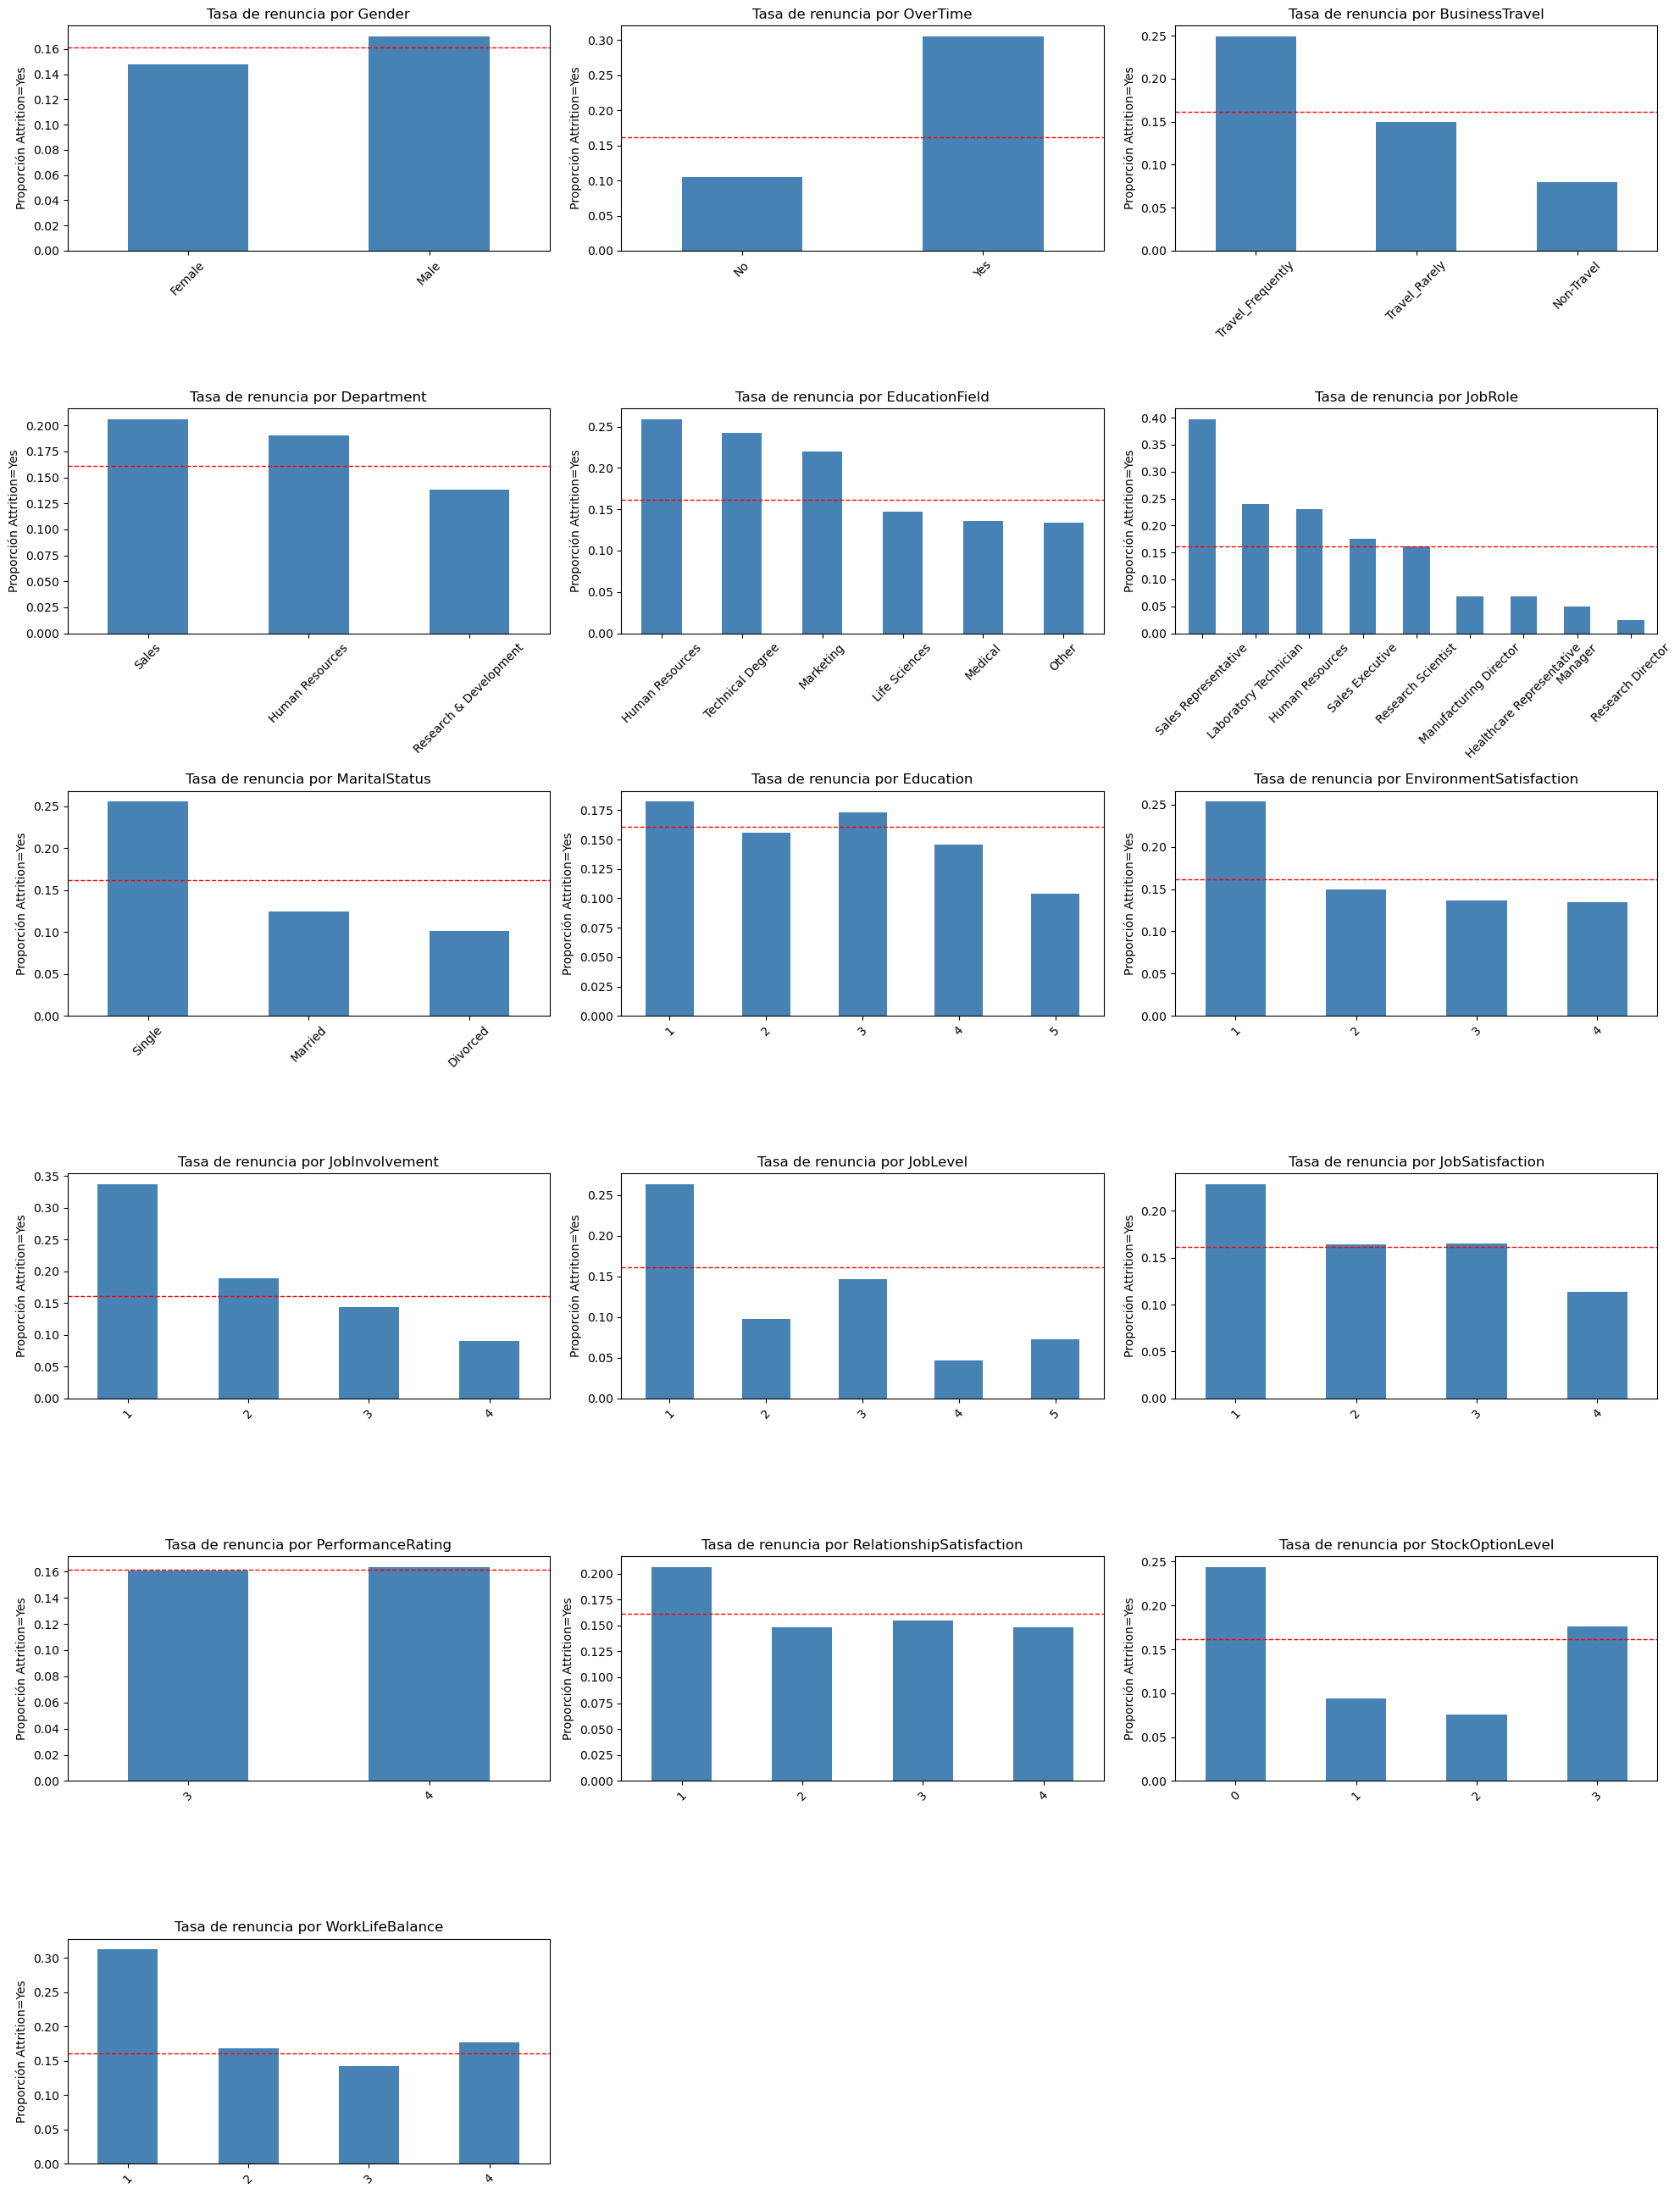

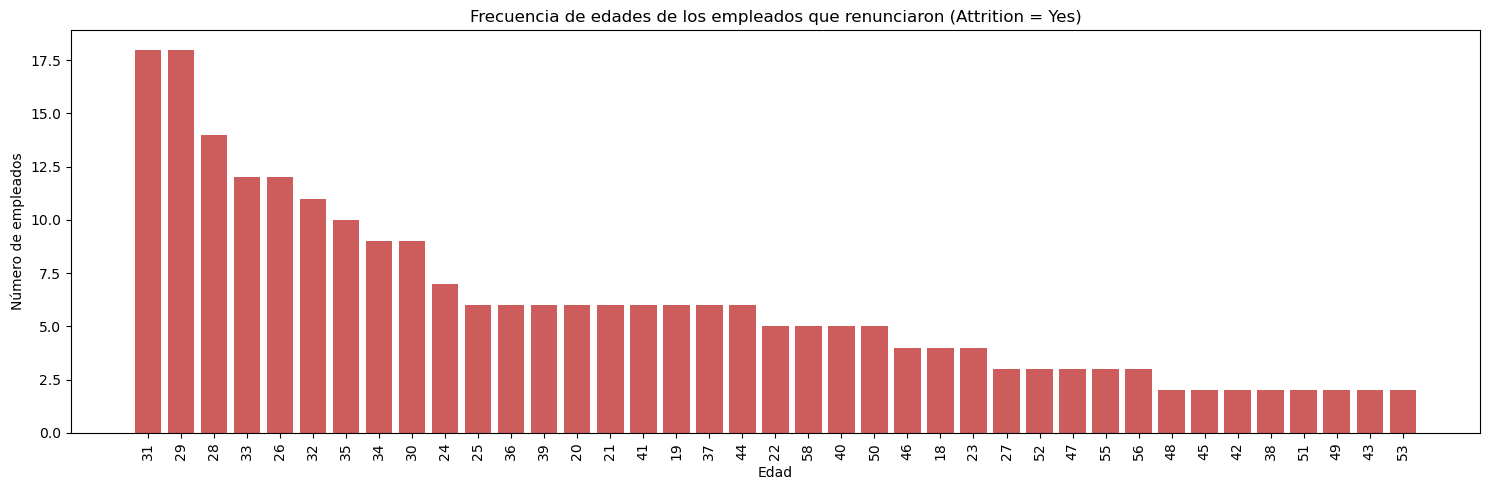

Edades con más renuncias:
 Age
31    18
29    18
28    14
33    12
26    12
Name: count, dtype: int64

% de quienes renunciaron con 30 años o menos: 42.2%
% de toda la plantilla con 30 años o menos:      26.3%


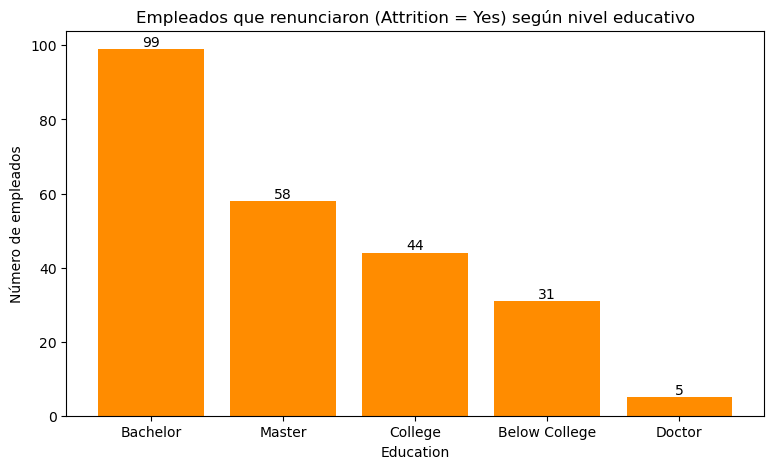

               empleados  renuncias   tasa
Edu                                       
Bachelor             572         99  0.173
Master               398         58  0.146
College              282         44  0.156
Below College        170         31  0.182
Doctor                48          5  0.104


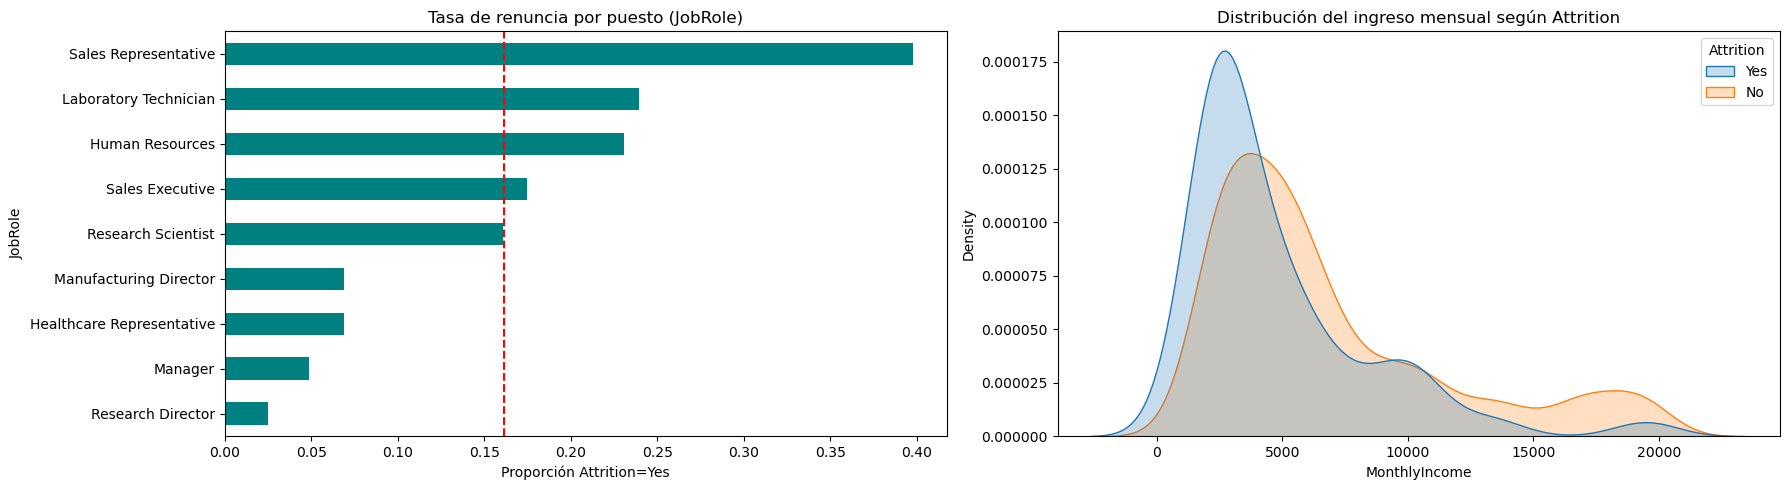

In [46]:

# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++
# Incluye en esta sección todas las celdas que consideres necesarias.

# a) Análsis y gráficos

# Se parte del DataFrame df (sin las 4 variables eliminadas) y de las listas vars_* definidas arriba.
# 1) Variable de salida
print("Proporción de cada clase en Attrition:")
print(df['Attrition'].value_counts(normalize=True).round(3))

# 2) Asimetría de las variables numéricas
print("\nAsimetría de las variables numéricas:")
print(df[vars_num].skew().sort_values(ascending=False).round(2))

# 3) Variables numéricas 
fig, axes = plt.subplots(4, 4, figsize=(20, 14))
axes = axes.flatten()
for i, col in enumerate(vars_num):
    sns.boxplot(data=df, x='Attrition', y=col, hue='Attrition', palette='Set2', legend=False, ax=axes[i])
    axes[i].set_title(col)
for j in range(len(vars_num), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

# 4) Correlación entre variables numéricas
plt.figure(figsize=(12, 9))
sns.heatmap(df[vars_num].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Correlación entre variables numéricas')
plt.show()

# 5) Tasa de renuncia (Attrition=Yes) por nivel de cada variable categórica
tasa_global = (df['Attrition'] == 'Yes').mean()
vars_cat = vars_bin + vars_nom + vars_ord
fig, axes = plt.subplots(6, 3, figsize=(20, 26))
axes = axes.flatten()
for i, col in enumerate(vars_cat):
    tasa = (df['Attrition'] == 'Yes').groupby(df[col]).mean()
    if col in vars_nom:
        tasa = tasa.sort_values(ascending=False)
    tasa.plot(kind='bar', ax=axes[i], color='steelblue')
    axes[i].axhline(tasa_global, color='red', linestyle='--', linewidth=1)
    axes[i].set_title(f'Tasa de renuncia por {col}')
    axes[i].set_ylabel('Proporción Attrition=Yes')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)
for j in range(len(vars_cat), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()


# b) Gráfico age-attrition[yes]

edad_yes = df.loc[df['Attrition'] == 'Yes', 'Age'].value_counts().sort_values(ascending=False)

plt.figure(figsize=(15, 5))
plt.bar(edad_yes.index.astype(str), edad_yes.values, color='indianred')
plt.title('Frecuencia de edades de los empleados que renunciaron (Attrition = Yes)')
plt.xlabel('Edad')
plt.ylabel('Número de empleados')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("Edades con más renuncias:\n", edad_yes.head(5))
print("\n%% de quienes renunciaron con 30 años o menos: %.1f%%" % (100 * (df.loc[df['Attrition']=='Yes','Age'] <= 30).mean()))
print("%% de toda la plantilla con 30 años o menos:      %.1f%%" % (100 * (df['Age'] <= 30).mean()))

# c) Gráfico education-attrition[yes]

etiquetas_edu = {1: 'Below College', 2: 'College', 3: 'Bachelor', 4: 'Master', 5: 'Doctor'}

edu_yes = df.loc[df['Attrition'] == 'Yes', 'Education'].map(etiquetas_edu).value_counts()  # ya viene de mayor a menor

plt.figure(figsize=(9, 5))
barras = plt.bar(edu_yes.index, edu_yes.values, color='darkorange')
plt.bar_label(barras)
plt.title('Empleados que renunciaron (Attrition = Yes) según nivel educativo')
plt.xlabel('Education')
plt.ylabel('Número de empleados')
plt.show()

# Como el número de renuncias depende del tamaño de cada grupo, comparamos también la tasa:
resumen_edu = df.assign(Edu=df['Education'].map(etiquetas_edu)).groupby('Edu')['Attrition'].agg(
    empleados='count', renuncias=lambda s: (s == 'Yes').sum(), tasa=lambda s: (s == 'Yes').mean()).sort_values('renuncias', ascending=False)
print(resumen_edu.round(3))

# d) [gráfico opcional]

# d) Gráficos adicionales: (1) tasa de renuncia por puesto y (2) ingreso mensual según Attrition
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

tasa_puesto = (df['Attrition'] == 'Yes').groupby(df['JobRole']).mean().sort_values()
tasa_puesto.plot(kind='barh', ax=axes[0], color='teal')
axes[0].axvline(tasa_global, color='red', linestyle='--')
axes[0].set_title('Tasa de renuncia por puesto (JobRole)')
axes[0].set_xlabel('Proporción Attrition=Yes')

sns.kdeplot(data=df, x='MonthlyIncome', hue='Attrition', common_norm=False, fill=True, ax=axes[1])
axes[1].set_title('Distribución del ingreso mensual según Attrition')

plt.tight_layout()
plt.show()


# ++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++



**Observaciones de los análisis 6a–6d y decisiones de transformación**

* **Variable de salida:** 83.9% No y 16.1% Yes, por lo que hay desbalanceo (se retoma en 6e y 5e).
* **Numéricas:** varias tienen asimetría positiva y valores atípicos: `YearsSinceLastPromotion` (≈1.98), `YearsAtCompany` (≈1.76), `MonthlyIncome` (≈1.37), `TotalWorkingYears` (≈1.12), `NumCompaniesWorked` (≈1.03). Los valores atípicos son legítimos (empleados con mucha antigüedad o con sueldos altos), por lo que no los elimino, sino que reduzco su influencia con **PowerTransformer (Yeo-Johnson)**, que además centra y escala. Esto también es necesario por las escalas tan distintas (por ejemplo `MonthlyRate` en miles frente a `Age` en decenas), pues KNN y la regularización de la regresión logística son sensibles a la escala.
* **Correlación:** hay variables muy relacionadas entre sí (`MonthlyIncome`–`JobLevel` ≈ 0.95, `TotalWorkingYears`–`JobLevel` ≈ 0.78, `YearsAtCompany`–`YearsWithCurrManager`/`YearsInCurrentRole` ≈ 0.77). Hay multicolinealidad, lo que justifica probar las regresiones con regularización L1, L2 y Elastic Net, que estabilizan los coeficientes. `DailyRate`, `HourlyRate` y `MonthlyRate` casi no se relacionan con nada ni se ven diferentes entre quienes renuncian y quienes no, pero las dejo y que el modelo regularizado decida su peso.
* **Ordinales:** ya vienen codificadas como números que conservan el orden (por ejemplo 1–4). Uso `OrdinalEncoder` para conservar el orden y `MinMaxScaler` para llevarlas a [0, 1]. En la tasa de renuncia se nota un patrón casi monótono: `JobSatisfaction` baja de 22.8% (nivel 1) a 11.3% (nivel 4); `JobLevel` de 26.3% (nivel 1) a 4.7% (nivel 4); y `WorkLifeBalance` = 1 llega a 31.2%.
* **Binarias:** `OverTime` es de lo más fuerte (30.5% de renuncia con horas extra contra 10.4% sin ellas). `Gender` casi no separa (14.8% mujeres, 17.0% hombres). Se codifican con `OrdinalEncoder` (0/1).
* **Nominales:** `JobRole` (Sales Representative 39.8% contra Research Director 2.5%), `BusinessTravel` (Travel_Frequently 24.9% contra Non-Travel 8.0%) y `MaritalStatus` (Single 25.5% contra Divorced 10.1%) presentan diferencias claras. Se codifican con `OneHotEncoder(handle_unknown='ignore')` porque no tienen orden.
* **6b (Age):** las renuncias se concentran entre los 26 y 35 años; las edades 29 y 31 son las de más casos (18 cada una). El 42% de quienes renunciaron tiene 30 años o menos, aunque ese grupo es solo el 26% de la plantilla, es decir, la renuncia está sobrerrepresentada en los jóvenes.
* **6c (Education):** en número absoluto el nivel Bachelor concentra más renuncias (99), seguido de Master (58), College (44), Below College (31) y Doctor (5). Pero eso se debe principalmente al tamaño de cada grupo (Bachelor tiene 572 empleados). En tasa, las diferencias son pequeñas (de 18.2% en Below College a 10.4% en Doctor), así que la escolaridad parece un factor poco discriminante.
* **6d:** la tasa de renuncia por puesto confirma que los puestos operativos y de ventas (Sales Representative, Laboratory Technician, Human Resources) pierden más gente que los puestos directivos. Además, el ingreso mensual de quienes renuncian se concentra en valores bajos (mediana de 3,202 contra 5,204 de quienes se quedan).

**e) ¿Qué es más costoso, los Falsos Negativos o los Falsos Positivos?**

++++++++ Inicia la sección de agregar texto: ++++++++++++

Para la empresa suele ser **más costoso un Falso Negativo (FN)**: no detectar a un empleado que sí va a renunciar. Cuando la persona se va sin que hubiera una oportunidad de intervenir, la empresa paga el costo completo de la rotación: reclutamiento, capacitación, el tiempo de curva de aprendizaje del reemplazo, entre otros.

En cambio, un **Falso Positivo (FP)**, es decir, una falsa alarma sobre alguien que en realidad no pensaba irse, tiene un costo normalmente menor: una conversación de retención, una revisión de carga de trabajo o un incentivo que quizá no era necesario. No es costo cero pero definitivamente no es una inversión grande en comparación.

Por eso en este problema interesa dar más peso a la **sensibilidad (recall) de la clase Yes**, aceptando algunas falsas alarmas. De igual forma, se pueden dar caso donde un director renuncie, esto no es lo mismo que un puesto de entrada renuncie.

++++++++ Termina la sección de agregar texto: ++++++++++++


# **Ejercicio 7:**

#### **Utiliza las clases Pipeline y ColumnTransformer de Sklearn para definir las transformaciones que deberás aplicar a cada variable y de acuerdo a su tipo considerado previamente.**



In [47]:
# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++


# NUMÉRICAS:
numericas_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),            
    ('power', PowerTransformer(method='yeo-johnson'))])      
numericas_pipeline_nombres = vars_num

# ORDINALES:
catOrd_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),  
    ('minmax', MinMaxScaler())])                                                       
catOrd_pipeline_nombres = vars_ord

# BINARIAS:
catBin_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))])  
catBin_pipeline_nombres = vars_bin

# NOMINALES:
catNom_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))])   
catNom_pipeline_nombres = vars_nom



columnasTransformer = ColumnTransformer(transformers=[
    ('num', numericas_pipeline, numericas_pipeline_nombres),
    ('ord', catOrd_pipeline,    catOrd_pipeline_nombres),
    ('bin', catBin_pipeline,    catBin_pipeline_nombres),
    ('nom', catNom_pipeline,    catNom_pipeline_nombres)],
    remainder='drop')



# ++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++

* #### **Vamos a utilizar validación cruzada, por lo que decidimos para esta actividad reagrupar los conjuntos de entrenamiento y validación en un solo DataFrame.**

* #### **Al resultado obtenido los llamaremos Xtv y ytv.**


In [48]:
Xtv = pd.concat([Xtrain, Xval], axis=0)
ytv = pd.concat([ytrainT, yvalT], axis=0)


print("Dimensión del conjunto Train+Val:")
print(Xtv.shape)
print(ytv.shape)

Dimensión del conjunto Train+Val:
(1249, 30)
(1249, 1)


# **Ejercicio 8:**

#### **Entrenamiento y ajuste de hiperparámetros**

#### **a) Busca los mejores hiperparámetros para cada modelo, de manera que no estén subentrenados con respecto a la métrica de la exactitud (accuracy).**

#### **b) Incluye tus comentarios sobre el resultado obtenido.**



#### **NOTA-1: En dado caso, cuando mucho uno de los modelos podría quedar subentrenado.**

#### **NOTA-2: Por el momento estamos usando la métrica de la exactitud (accuracy). El objetivo de esta actividad es que sepas entrenar modelos sin que resulten subentrenados o sobreentrenados, independientemente de la métrica a considerar. En próximas semanas seguiremos con el estudio de las otras métricas para abordar de mejor manera los problemas y obtener mejores resultados.**

En relación a la variante de Validación Cruzada "RepeatedStratifiedKFold" utilizada en este ejercicio, puedes consultar la siguiente liga:

  https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html


>> LR 0.886 (0.015)
>> LASSO 0.887 (0.014)
>> RIDGE 0.888 (0.013)
>> EN 0.888 (0.015)
>> KNN 0.851 (0.009)


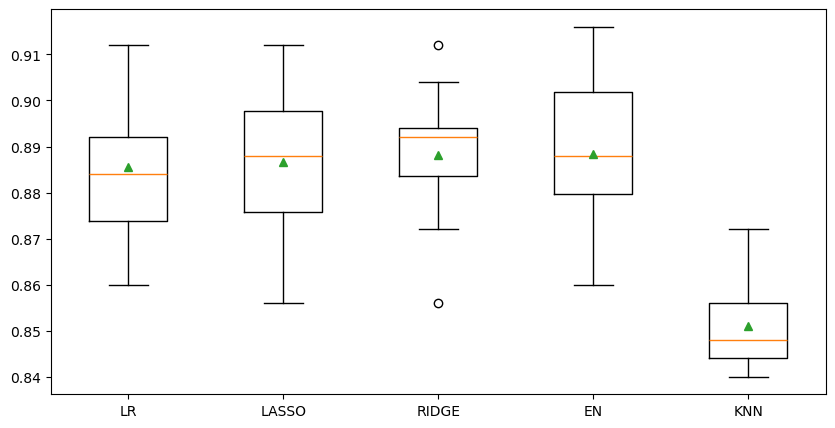

In [49]:
# 8a) Ajuste de hiperparámetros.
#     En cada modelo que utilcemos a continuación, utiliza la semilla "random_state=1"
#     indicada, para obtener la repetibilidad de los resultados en la manera de lo
#     posible. Es decir, este argumento y valor no deberás modificarlo.

# ++++++++++ Inicia sección para agregar tu código ++++++++++++++++++++++++


def mis_modelos():
  modelos, nombres = list(), list()

  # LR - Regresión Logística sin regularización:
  modelos.append(LogisticRegression(penalty=None,  # Este valor de "None" no lo debes cambiar. Define al modelo sin regularización.
                                    solver='lbfgs', max_iter=5000,
                                    random_state=1))
  nombres.append('LR')



  # Lasso - Regresión Logística con regularización L1:
  modelos.append(LogisticRegression(penalty='l1',
                                    solver='saga', C=0.5, max_iter=5000,
                                    random_state=1))
  nombres.append('LASSO')



  # Ridge - Regresión Logística con regularización L2:
  modelos.append(LogisticRegression(penalty='l2',
                                    solver='lbfgs', C=0.3, max_iter=5000,
                                    random_state=1))
  nombres.append('RIDGE')



  # Elastic_Net - - Regresión Logística con regularización L1 y L2:
  modelos.append(LogisticRegression(penalty='elasticnet',
                                    solver='saga', C=0.5, l1_ratio=0.5, max_iter=5000,
                                    random_state=1))
  nombres.append('EN')



  # KNN - K-Vecinos más cercanos:
  modelos.append(KNeighborsClassifier(n_neighbors=15, weights='uniform', metric='manhattan'))
  nombres.append('KNN')

  return modelos, nombres




# ++++++++++ Termina sección para agregar tu código ++++++++++++++++++++++++


# Pasamos al entrenamiento de los modelos.
# Hay obviamente varias maneras de llevar a cabo el entrenamiento,
# pero por el momento supongamos que lo hacemos de la manera siguiente:

modelos, nombres = mis_modelos()  # accesando los modelos.
resultados = list()    # para guardar los resultados en esta lista.

# Iterando y entrenando sobre cada modelo:
for i in range(len(modelos)):

  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelos[i])])   # Conjuntamos Transformaciones y modelos en un Pipeline.

  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)     # Aplicando una de las variantes de Validación Cruzada.

  scores = cross_val_score(pipeline, Xtv, np.ravel(ytv), scoring='accuracy', cv=cv1)   # Entrenando y generando los resultados con la exactitud (accuracy).


  resultados.append(scores)    # Guardamos los resultados en la lista.
  print('>> %s %.3f (%.3f)' % (nombres[i], np.nanmean(scores), np.nanstd(scores)))  # Desplegando los promedios de cada modelo.


plt.figure(figsize=(10,5))
plt.boxplot(resultados, tick_labels=nombres, showmeans=True)   # Gráficos de caja para una comparación visual de los resultados.
plt.show()


**8b) Comentarios sobre los resultados y modelos obtenidos. En particular indica cuál consideras el mejor modelo. ¿Alguno quedó subentrenado y ya no se pudo mejorar su desempeño?**

++++++++ Inicia la sección de agregar texto: ++++++++++++

Resultados de la validación cruzada (5 folds x 3 repeticiones, exactitud promedio y desviación estándar), contra un umbral ingenuo de 0.839:

| Modelo | Exactitud (std) |
|---|---|
| LR (sin regularización) | 0.8855 (0.0146) |
| LASSO (L1, C=0.5) | 0.8866 (0.0140) |
| RIDGE (L2, C=0.3) | 0.8882 (0.0134) |
| ELASTIC NET (C=0.5, l1_ratio=0.5) | 0.8884 (0.0147) |
| KNN (k=15, distancia Manhattan) | 0.8511 (0.0086) |

* Los cuatro modelos de regresión logística rinden prácticamente igual como se ve en la tabla de arriba: las diferencias son menores que la desviación estándar entre folds. Todos superan con claridad el umbral de 0.839, por lo que ninguno está subentrenado.
* Considero **Ridge** el mejor modelo: tiene la exactitud promedio prácticamente igual a la de Elastic Net (diferencia de 0.0002), la desviación estándar más baja (el más estable), es más simple y con un solver determinista (lbfgs). La regularización ayuda ligeramente frente a la regresión sin regularizar (0.8855), lo cual es consistente con la multicolinealidad que se vio entre variables.
* **KNN es el que quedó al borde del subentrenamiento.** Supera el umbral (0.851 contra 0.839). Probé distintos valores de k (3 a 31), pesos (uniform/distance) y métrica (euclidiana/Manhattan): con k pequeño se sobreajusta al ruido (k=3 llegó a 0.825, por debajo del umbral) y con k grande tiende a la clase mayoritaria (≈0.844); lo mejor fue ≈0.851 con Manhattan y k entre 9 y 15. No fue posible mejorarlo más. 

++++++++ Termina la sección de agregar texto: ++++++++++++


# **Ejercicio 9:**

* #### **Utiliza el mejor modelo encontrado en el paso anterior, los datos Xtv, ytv, y realiza ahora una búsqueda de malla con validación cruzada para tratar de mejorar el desempeño de este modelo.**

* #### **Sigue utilizando la métrica de la exactitud (accuracy).**

* #### **Verifica además que el modelo no esté subentrenado o sobreentrenado.**

* #### **Llama "resultado_malla" al mejor modelo ajustado.**




* **NOTA-1: Para esta actividad diremos que el modelo no está sobreentrenado si la diferencia entre Train y Validation es menor al 3%.**


* **NOTA-2: Puedes utilizar GridSearchCV, o bien, RandomizedSearchCV. La documentación la puedes consultar en las siguientes ligas:**

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html


In [50]:
# +++++++++ Inicia sección para incluir tu código ++++++++++++++++++++++++




# Mejor modelo del ejercicio anterior: Regresión logística con regularización L2 (Ridge).
# Se busca la mejor combinación de C (fuerza de regularización) y solver, con la misma validación cruzada.
pipeline_ridge = Pipeline(steps=[('ct', columnasTransformer),
                                 ('m', LogisticRegression(penalty='l2', max_iter=5000, random_state=1))])

malla = {'m__C': [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1, 2],
         'm__solver': ['lbfgs', 'liblinear']}

cv2 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)

resultado_malla = GridSearchCV(pipeline_ridge, param_grid=malla, scoring='accuracy', cv=cv2,
                               return_train_score=True, n_jobs=-1)
resultado_malla.fit(Xtv, np.ravel(ytv))




# +++++++++ Termina sección para incluir tu código ++++++++++++++++++++++++


print("Desempeño del mejor modelo con la métrica de Exactitud (Accuracy)")
print("-"*65)
print("Mejor modelo: %f usando los hiperparámetros %s" % (resultado_malla.best_score_, resultado_malla.best_params_))
print('Promedios Train mean(std): %.2f%% (%.4f%%)' % (100*np.nanmean(resultado_malla.cv_results_['mean_train_score']),
                                                 100*np.nanmean(resultado_malla.cv_results_['std_train_score'])))
print('Promedios Val mean(std): %.2f%% (%.4f%%)' % (100*resultado_malla.cv_results_['mean_test_score'].mean(),
                                               100*resultado_malla.cv_results_['std_test_score'].mean()))


Desempeño del mejor modelo con la métrica de Exactitud (Accuracy)
-----------------------------------------------------------------
Mejor modelo: 0.888707 usando los hiperparámetros {'m__C': 0.7, 'm__solver': 'lbfgs'}
Promedios Train mean(std): 89.94% (0.4877%)
Promedios Val mean(std): 88.38% (1.4017%)


In [51]:
# Verificación de subentrenamiento / sobreentrenamiento del mejor modelo encontrado
i = resultado_malla.best_index_
train_mejor = resultado_malla.cv_results_['mean_train_score'][i]
val_mejor   = resultado_malla.cv_results_['mean_test_score'][i]
baseline    = 1 - np.mean(np.ravel(ytv))      # exactitud de siempre predecir "No"

print("Exactitud Train (mejor modelo):      %.4f" % train_mejor)
print("Exactitud Validation (mejor modelo): %.4f" % val_mejor)
print("Diferencia Train - Validation:       %.2f%%" % (100 * (train_mejor - val_mejor)))
print("Umbral del modelo ingenuo:           %.4f" % baseline)
print("¿Sobreentrenado (diferencia >= 3%)?   ", "Sí" if (train_mejor - val_mejor) >= 0.03 else "No")
print("¿Subentrenado (Val <= umbral)?       ", "Sí" if val_mejor <= baseline else "No")

res = pd.DataFrame(resultado_malla.cv_results_)[['param_m__C', 'param_m__solver', 'mean_train_score', 'mean_test_score']]
res['diferencia'] = res['mean_train_score'] - res['mean_test_score']
res.sort_values('mean_test_score', ascending=False).head(6).round(4)

Exactitud Train (mejor modelo):      0.9053
Exactitud Validation (mejor modelo): 0.8887
Diferencia Train - Validation:       1.66%
Umbral del modelo ingenuo:           0.8391
¿Sobreentrenado (diferencia >= 3%)?    No
¿Subentrenado (Val <= umbral)?        No


,param_m__C,param_m__solver,mean_train_score,mean_test_score,diferencia
10,0.7,lbfgs,0.9053,0.8887,0.0166
7,0.3,liblinear,0.9035,0.8884,0.0151
6,0.3,lbfgs,0.9033,0.8882,0.0151
11,0.7,liblinear,0.9053,0.8882,0.0171
8,0.5,lbfgs,0.9053,0.8876,0.0177
9,0.5,liblinear,0.9055,0.8876,0.0178


**Comentarios del Ejercicio 9.** La búsqueda de malla (8 valores de C x 2 solvers, con 5x3 validaciones cruzadas) encontró como mejor configuración C = 0.7 con el solver `lbfgs`, con una exactitud de validación de ≈0.8887, apenas por encima del 0.8882 que ya tenía Ridge con C = 0.3. Es decir, el modelo ya estaba cerca de su techo y el ajuste fino aporta una mejora mínima. Los solvers `lbfgs` y `liblinear` dan resultados casi idénticos, como se espera porque resuelven el mismo problema convexo.

* **No está subentrenado:** su exactitud (≈0.889) supera por unos 5 puntos el umbral del modelo ingenuo (≈0.839).
* **No está sobreentrenado:** la diferencia entre Train (≈0.905) y Validation (≈0.889) es de unos 1.7 puntos porcentuales, menor al límite de 3% establecido. Valores de C mayores (menos regularización) aumentan la brecha (≈2% con C=2) sin mejorar la validación, mientras que valores muy pequeños (C=0.05) bajan tanto Train como Validation, es decir, empiezan a subentrenar. C = 0.7 queda en un buen punto medio.

# **Ejercicio 10:**

#### **Finalmente, usando el conjunto de prueba (Test) responde los siguientes incisos:**

#### **a) Obtener el desempeño final del mejor modelo con el reporte de métricas classification_report() de Sklearn.**

#### **b) Obtener la matriz de confusión del mejor modelo.**

#### **c) Indica como se leen o interpretan los valores VP, VN, FP, FN obtenidos y de acuerdo al contexto del problema.**

#### **d) Realiza un análisis de importancia de los factores o características e incluye tus comentarios.**



In [52]:
# a) Reporte del desempeño con classification_report():

# +++++++++ Inicia sección para incluir tu código ++++++++++++++++++++++++


ypred = resultado_malla.predict(Xtest)      # el mejor modelo (re-ajustado con Train+Val) predice sobre Test

print(classification_report(np.ravel(ytestT), ypred,
                            target_names=['No','Yes'], digits=3))
print('ROC-AUC en Test: %.3f' % metrics.roc_auc_score(np.ravel(ytestT), resultado_malla.predict_proba(Xtest)[:, 1]))

# +++++++++ Termina sección para incluir tu código ++++++++++++++++++++++++


              precision    recall  f1-score   support

          No      0.890     0.962     0.925       185
         Yes      0.667     0.389     0.491        36

    accuracy                          0.869       221
   macro avg      0.778     0.676     0.708       221
weighted avg      0.854     0.869     0.854       221

ROC-AUC en Test: 0.731


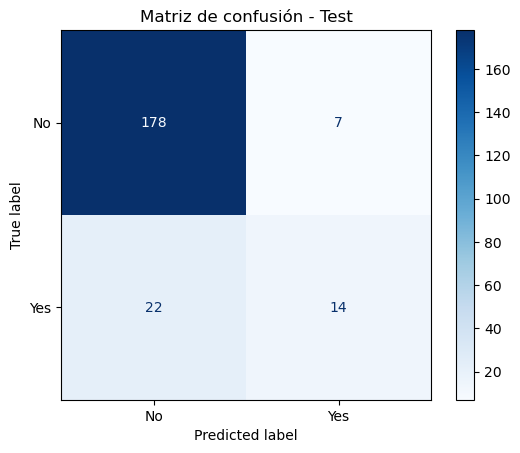

VN = 178 | FP = 7 | FN = 22 | VP = 14


In [53]:
# b) Matriz de confusión:

# +++++++++ Inicia sección para incluir tu código ++++++++++++++++++++++++


ConfusionMatrixDisplay.from_predictions(np.ravel(ytestT), ypred, display_labels=['No', 'Yes'], cmap='Blues')
plt.title('Matriz de confusión - Test')
plt.show()

vn, fp, fn, vp = metrics.confusion_matrix(np.ravel(ytestT), ypred).ravel()
print("VN =", vn, "| FP =", fp, "| FN =", fn, "| VP =", vp)


# +++++++++ Termina sección para incluir tu código ++++++++++++++++++++++++


*  c) Interpretación de VP, VF, FP, FN.
#### +++++++++ Inicia sección para incluir tus comentarios ++++++++++++++++++++++++

En este problema la clase positiva es **Yes = el empleado renuncia**. Sobre los 221 empleados del conjunto de prueba (36 renunciaron y 185 se quedaron):

* **VP (verdaderos positivos) = 14:** empleados que el modelo marcó como "se irá" y que efectivamente renunciaron. Son los casos donde el modelo sirve para actuar a tiempo.

* **VN (verdaderos negativos) = 178:** empleados que el modelo marcó como "se queda" y que siguieron en la empresa. No requieren intervención.

* **FP (falsos positivos) = 7:** empleados que el modelo marcó como "se irá" pero que se quedaron. Son falsas alarmas: se invertiría atención o recursos de retención que no eran necesarios.

* **FN (falsos negativos) = 22:** empleados que el modelo marcó como "se queda" pero que renunciaron. Son los casos que la empresa no ve venir y que ya no puede intentar retener.

Con esto, la exactitud es (14 + 178) / 221 ≈ 0.869. Pero los números de la clase Yes son más reveladores: la **precisión** es 14/(14+7) ≈ 0.67 (cuando el modelo avisa, acierta dos de cada tres veces) y el **recall** es 14/(14+22) ≈ 0.39 (solo detecta a 4 de cada 10 de quienes realmente renuncian). Tenemos 22 renuncias que el modelo no detecta contra solo 7 falsas alarmas.

#### +++++++++ Termina sección para incluir tus comentarios ++++++++++++++++++++++++

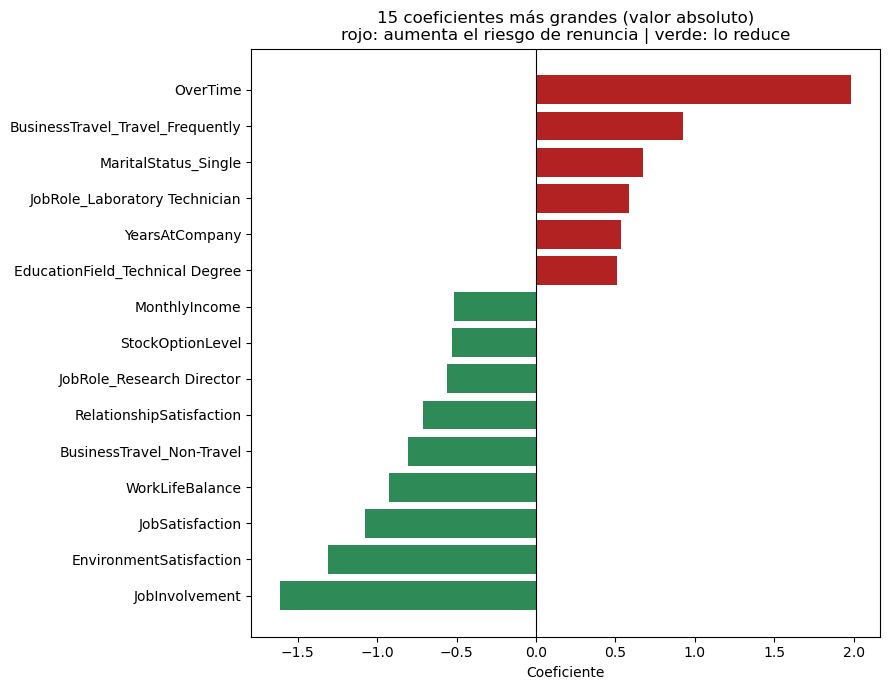

Razón de momios (odds ratio) = exp(coef):
OverTime                            7.28
BusinessTravel_Travel_Frequently    2.52
MaritalStatus_Single                1.96
JobRole_Laboratory Technician       1.80
YearsAtCompany                      1.70
EducationField_Technical Degree     1.66
StockOptionLevel                    0.59
MonthlyIncome                       0.59
JobRole_Research Director           0.57
RelationshipSatisfaction            0.49
BusinessTravel_Non-Travel           0.45
WorkLifeBalance                     0.40
JobSatisfaction                     0.34
EnvironmentSatisfaction             0.27
JobInvolvement                      0.20


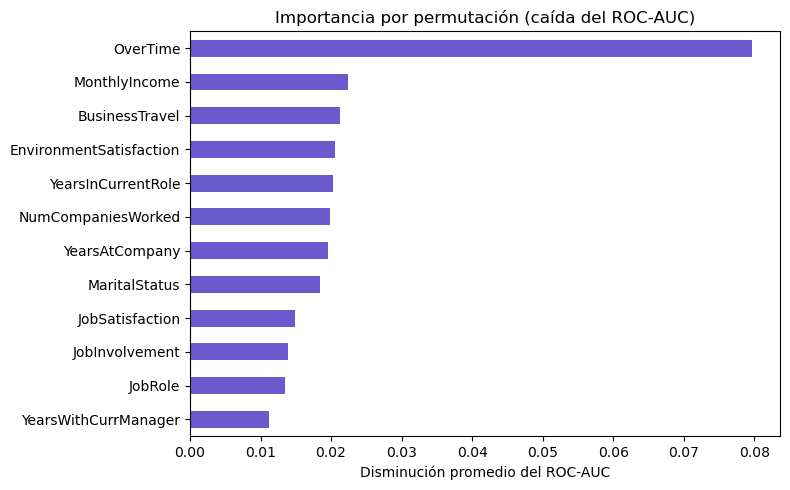

OverTime                   0.0797
MonthlyIncome              0.0224
BusinessTravel             0.0213
EnvironmentSatisfaction    0.0205
YearsInCurrentRole         0.0203
NumCompaniesWorked         0.0198
YearsAtCompany             0.0196
MaritalStatus              0.0184
JobSatisfaction            0.0149
JobInvolvement             0.0139
JobRole                    0.0134
YearsWithCurrManager       0.0112


In [54]:
# 10d) Inportancia de factores

# +++++++++ Inicia sección para incluir tu código ++++++++++++++++++++++++


from sklearn.inspection import permutation_importance

modelo_final = resultado_malla.best_estimator_

# (1) Coeficientes de la regresión logística (las variables ya están en escalas comparables tras el ColumnTransformer)
nombres_feat = [n.split('__', 1)[1] for n in modelo_final.named_steps['ct'].get_feature_names_out()]
coefs = pd.Series(modelo_final.named_steps['m'].coef_[0], index=nombres_feat)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).head(15).index).sort_values()

plt.figure(figsize=(9, 7))
plt.barh(top.index, top.values, color=['seagreen' if v < 0 else 'firebrick' for v in top])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('15 coeficientes más grandes (valor absoluto)\nrojo: aumenta el riesgo de renuncia | verde: lo reduce')
plt.xlabel('Coeficiente')
plt.tight_layout()
plt.show()
print("Razón de momios (odds ratio) = exp(coef):")
print(np.exp(top).round(2).sort_values(ascending=False).to_string())

# (2) Importancia por permutación sobre las variables ORIGINALES (más estable: se calcula con Train+Val)
pi = permutation_importance(modelo_final, Xtv, np.ravel(ytv), scoring='roc_auc', n_repeats=20, random_state=1, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=Xtv.columns).sort_values(ascending=False).head(12)

plt.figure(figsize=(8, 5))
imp.sort_values().plot(kind='barh', color='slateblue')
plt.title('Importancia por permutación (caída del ROC-AUC)')
plt.xlabel('Disminución promedio del ROC-AUC')
plt.tight_layout()
plt.show()
print(imp.round(4).to_string())


# +++++++++ Termina sección para incluir tu código ++++++++++++++++++++++++



*  **10d) Comentarios sobre los resultados sobre el análisis de importancia de factores o características**

#### +++++++++ Inicia sección para incluir tus comentarios ++++++++++++++++++++++++

Utilicé dos miradas complementarias: (1) los **coeficientes** de la regresión logística (como las variables numéricas quedaron estandarizadas y las ordinales en [0, 1], su magnitud es razonablemente comparable) y (2) la **importancia por permutación** (cuánto cae el ROC-AUC al desordenar cada variable original).

* **El factor más importante es, por mucho, `OverTime` (horas extra).** Su razón de momios es ≈ 7.3 (coeficiente ≈ 1.99): con todo lo demás igual, trabajar horas extra multiplica por ~7 los momios de renunciar. En la permutación su caída del AUC (≈ 0.08) es casi cuatro veces la de la siguiente variable. Es consistente con lo visto en 6a (30.5% de renuncia con horas extra contra 10.4% sin ellas).
* **Factores que aumentan el riesgo:** viajar con frecuencia (`BusinessTravel_Travel_Frequently`, OR ≈ 2.5), ser soltero (`MaritalStatus_Single`, OR ≈ 2.0), ser técnico de laboratorio (OR ≈ 1.8), y, con un efecto más moderado (quedan fuera de la gráfica de los 15 mayores), haber trabajado en muchas empresas (`NumCompaniesWorked`), vivir lejos (`DistanceFromHome`) y llevar más tiempo sin ascenso (`YearsSinceLastPromotion`).
* **Factores que lo reducen:** mayor involucramiento en el trabajo (`JobInvolvement`, OR ≈ 0.20), satisfacción con el entorno (`EnvironmentSatisfaction`, ≈ 0.27) y con el puesto (`JobSatisfaction`, ≈ 0.34), buen balance vida-trabajo (≈ 0.40), no viajar (≈ 0.45), mejor relación con los compañeros (≈ 0.49), tener opciones de acciones y un mayor ingreso mensual (≈ 0.59 cada uno). En la permutación, además de `OverTime`, destacan `MonthlyIncome`, `BusinessTravel`, `EnvironmentSatisfaction`, `YearsInCurrentRole`, `NumCompaniesWorked` y `YearsAtCompany`.
* **Precauciones al interpretar:** (a) los coeficientes de las ordinales representan pasar del nivel más bajo al más alto, por eso parecen "grandes"; (b) las variables de antigüedad están muy correlacionadas entre sí (`YearsAtCompany` sale positiva y `YearsInCurrentRole`/`YearsWithCurrManager` negativas), por lo que no conviene interpretarlas por separado, sino como un bloque; (c) la importancia por permutación se calculó con Train+Val, es decir, con datos que el modelo ya vio, así que sirve para ordenar variables pero no para cuantificar su efecto; (d) son asociaciones, no causas.
* **Relación con la parte ética:** `MaritalStatus` aparece entre los factores relevantes y `Age` tiene un coeficiente moderado, mientras que `Gender` no destaca. Esto confirma lo discutido en el Ejercicio 3: no se debería usar el estado civil ni la edad para tomar decisiones sobre las personas, y conviene revisar el desempeño por subgrupos.
* **Lo accionable para la empresa:** los factores que la organización sí puede modificar: horas extra, frecuencia de viajes, satisfacción y balance vida-trabajo, compensación y opciones de acciones, y las oportunidades de promoción.

#### +++++++++ Termina sección para incluir tus comentarios ++++++++++++++++++++++++

# **Ejercicio 11:**


### **Para terminar, responde las siguientes preguntas relacionadas con las implicaciones involucradas con la toma de decisiones basadas en los resultados de un modelo de aprendizaje automático. El objetivo es reflexionar sobre estas implicaciones y no dudes en compartir tus experiencias en caso de que te hayas enfrentado a una situación similar en tu trabajo.**

* **a) Si tu modelo predice e identifica con un alto porcentaje de exactitud quiénes de los colaboradores de la empresa estarán abandonando su puesto muy pronto, ¿cómo debería usarse esa información? Al responder, considera que es importante cuidar la parte ética y de privacidad de la información del colaborador.**

* **b) Con base a los resultados de la matriz de confusión, ¿qué tipo de error (FN o FP) está considerando como más costoso el modelo? En particular, ¿coincide con la respuesta que diste en el Ejercicio 6e?**

* **c) ¿Cómo comunicarías los resultados del modelo obtenido en esta actividad a un público no técnico, es decir, sin los conocimientos de temas de aprendizaje automático. Por ejemplo, supongamos que vas a comunicarle tus resultados a los directivos de la empresa o al personal del área de Recursos Humanos.**

* **d) ¿En cuáles ejercicios anteriores consideras que el (o los) modelo de lenguaje de gran tamaño LLM utilizado fue de mayor ayuda? ¿Por qué?**

* **e) Incluye tus conclusiones finales de la actividad.**

---

#### +++++++++ Inicia sección para incluir tus conclusiones ++++++++++++++++++++++++


* a) **Uso de la información.** La predicción debe usarse para **apoyar y retener**, no para castigar. Concretamente: (1) como una alerta temprana para que Recursos Humanos y el jefe directo tengan una conversación de acompañamiento (carga de trabajo, horas extra, plan de carrera, compensación); (2) con acceso restringido a un grupo mínimo de personas y con la información protegida; (3) preferentemente a nivel agregado (equipos, puestos, departamentos con más riesgo) para corregir causas de fondo, y solo a nivel individual con un propósito claro de retención; (4) nunca como base para dejar de dar ascensos, proyectos, capacitación o aumentos, ni mucho menos para prescindir de la persona; (5) con una decisión final humana, ya que el modelo es probabilístico y se equivoca (aquí deja pasar a 6 de cada 10 renuncias); y (6) con transparencia hacia los colaboradores sobre qué datos se usan y para qué, cumpliendo con el aviso de privacidad y la legislación de protección de datos personales. También hay que evitar atributos protegidos (edad, género, estado civil) como criterio de decisión, y revisar periódicamente que el modelo no perjudique a algún grupo.

* b) **Tipo de error.** El modelo comete **más Falsos Negativos (22) que Falsos Positivos (7)**. Es decir, en la práctica se comporta como si los FN fueran los menos costosos, o más bien, como si no distinguiera entre errores: el modelo se entrenó para maximizar la exactitud, que cuenta igual todos los errores y, con 84% de empleados que se quedan, lo más "rentable" es ser conservador y decir que casi nadie renuncia. **Esto no coincide con lo que respondí en el Ejercicio 6e**, donde argumenté que un FN es más costoso para la empresa que un FP. Para alinear el modelo con el costo real, habría que: usar `class_weight='balanced'`, bajar el umbral de decisión (por ejemplo de 0.5 a ≈0.3), optimizar recall, F2 o PR-AUC en la validación cruzada en lugar de la exactitud, y revisar la curva precisión-recall. A cambio aumentarían las falsas alarmas, lo cual es aceptable si las intervenciones son baratas.

* c) **Comunicación a un público no técnico.** Evitaría términos como regularización o hiperparámetros y usaría un lenguaje de negocio: "Analizamos el historial de 1,470 empleados (datos sintéticos de IBM) y construimos una herramienta que estima qué perfiles tienen más probabilidad de renunciar. Cuando la herramienta avisa que alguien está en riesgo, acierta en 2 de cada 3 casos; sin embargo, hoy solo detecta alrededor de 4 de cada 10 renuncias reales, así que es un apoyo, no una bola de cristal." Después compartiría lo que más importa para actuar: los factores que más se asocian con la salida son las **horas extra**, los **viajes frecuentes**, la **baja satisfacción** con el trabajo y el entorno, el **poco involucramiento** en el puesto y el **sueldo bajo**, especialmente en puestos de ventas y técnicos de laboratorio. Eso lo apoyaría con 2 o 3 gráficas sencillas (tasa de renuncia con y sin horas extra; por puesto; matriz de confusión explicada con "personas", no con VP/FP), y cerraría con recomendaciones concretas (revisar la carga de horas extra, planes de carrera y compensación en los puestos con mayor rotación), las limitaciones (datos sintéticos, no causalidad, posible sesgo) y los siguientes pasos (mejorar el recall, piloto controlado de retención y medir su efecto).

* d) **Ayuda del LLM.** Utilicé Claude (Anthropic) como apoyo. Me resultó más útil en: (1) **Ejercicio 7**, para estructurar los Pipelines y el ColumnTransformer y decidir qué transformación aplicar a cada tipo de variable; (2) **Ejercicios 8 y 9**, para sugernecias de hiperparámetros y revisar que no hubiera data-leakage ni sobreentrenamiento; (3) **Ejercicios 3, 6e y 11**, para la fluidez de mis ideas y contrastar la interpretación de las métricas; y (4) la **redacción** de los textos.

* e) **Conclusiones finales.**
  1. El conjunto de datos tiene 1,470 empleados con 16% de renuncias. Eliminé 4 variables sin valor (3 constantes y 1 identificador) y me quedé con 30 variables de entrada.
  2. Un modelo ingenuo que dijera siempre "no renuncia" ya obtiene 83.9% de exactitud, por lo que esa es la cifra mínima a superar. Los modelos de regresión logística llegaron a ≈88.7% en validación (≈86.9% en Test), mientras que KNN se quedó en ≈85%, apenas arriba del umbral.
  3. La regularización aportó muy poco (Ridge, Lasso y Elastic Net quedaron empatados), y la búsqueda de malla mejoró el modelo solo marginalmente. El techo parece estar en los datos y en la métrica, no en el ajuste de hiperparámetros. El modelo final no está subentrenado ni sobreentrenado (brecha Train-Val de ≈1.7 puntos).
  4. La exactitud es engañosa en este problema: el modelo final detecta solo 14 de 36 renuncias en Test (recall ≈ 0.39) con una precisión de ≈ 0.67. Para uso real hay que optimizar recall/F2/PR-AUC y ajustar el umbral, aceptando más falsas alarmas.
  5. Los factores que más se asocian con la renuncia (horas extra, viajes frecuentes, baja satisfacción e involucramiento, haber cambiado muchas veces de empleo, sueldo bajo) dan pistas accionables para Recursos Humanos, pero se trata de asociaciones, no de causas.
  6. Hay riesgos éticos y legales si se usan atributos como edad, género o estado civil. El modelo debe servir para apoyar y retener, con supervisión humana, transparencia y protección de datos.
  7. Como trabajo futuro: probar modelos de árboles/ensambles, `class_weight` y ajuste de umbral.

#### +++++++++ Termina sección para incluir tus conclusiones ++++++++++++++++++++++++

# >> **Fin de la Actividad de Rotación de Personal de la Semana 3** <<

Bibliografia:
- Géron, Aurélien (2022). Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow, 3rd Edition. O’Reilly. 